In [1]:
import os
import zipfile
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.utils import to_categorical
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetV2S, DenseNet121, InceptionResNetV2, ResNet50
from tensorflow.keras.callbacks import ModelCheckpoint
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils.class_weight import compute_class_weight
import cv2

In [2]:
UNIFIED_DATASET_PATH = "/Users/mac/Development/diploma/skin-mutation-detection/unified_dataset"
UNIFIED_ZIP_PATH = "/Users/mac/Development/diploma/skin-mutation-detection/unified_dataset/unified_dataset.zip"

In [ ]:
unzip_to = UNIFIED_DATASET_PATH
zip_path = UNIFIED_ZIP_PATH
with zipfile.ZipFile(zip, 'r') as zip_ref:
    zip_ref.extractall(unzip_to)

In [3]:
TRAIN_GROUNDTRUTH_PATH = os.path.join(UNIFIED_DATASET_PATH, "gt.csv")
TEST_GROUNDTRUTH_PATH = "/Users/mac/Development/diploma/skin-mutation-detection/ham10000/HAM10000_Test_GroundTruth_Updated.csv"
# TEST2_GROUNDTRUTH_PATH = "/teamspace/studios/this_studio/data/test/ISIC_2019_Test_GroundTruth.csv"

TRAIN_IMAGE_DIR = os.path.join(UNIFIED_DATASET_PATH, "images")
HAM_IMAGE_DIR = "/Users/mac/Development/diploma/skin-mutation-detection/ham10000/HAM10000_images_part_12"
# TEST2_IMAGE_DIR = "/teamspace/studios/this_studio/data/test/ISIC_2019_Test_Input"
SEGM_DIR = os.path.join(UNIFIED_DATASET_PATH, "segmentations")
MODEL_NAME = "efficientnetv2-s-onehot-deep-unified-no-segm"

IMG_SIZE = (456, 456)
BATCH_SIZE = 32
EPOCHS = 20
LABELS = ['MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC']

In [4]:
def read_ds(gnd_path):
    df = pd.read_csv(gnd_path)
    return df

def get_image_paths_and_labels(df, image_dir):
    image_paths = [os.path.join(image_dir, row['image'] + '.jpg') for _, row in df.iterrows()]
    labels = df[LABELS].values  # One-hot labels
    return image_paths, labels

train_groundtruth = read_ds(TRAIN_GROUNDTRUTH_PATH)
ham_groundtruth = read_ds(TEST_GROUNDTRUTH_PATH)
# test_groundtruth_2 = read_ds(TEST2_GROUNDTRUTH_PATH)

train_paths, train_labels = get_image_paths_and_labels(train_groundtruth, TRAIN_IMAGE_DIR)
# test_paths, test_labels = get_image_paths_and_labels(test_groundtruth, TEST_IMAGE_DIR)
test_paths_2, test_labels_2 = get_image_paths_and_labels(ham_groundtruth, HAM_IMAGE_DIR)

In [5]:
from sklearn.model_selection import train_test_split

train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    train_paths, train_labels, test_size=0.2, stratify=train_labels, random_state=42
)

val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels, test_size=0.5, stratify=temp_labels, random_state=42
)

In [ ]:
def load_image(file_path, label):
    img = tf.io.read_file(file_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.keras.applications.efficientnet.preprocess_input(img)
    return img, label

def load_image2(file_path, label):
    def py_process(path_str):
        import numpy as np
        import cv2
        import os

        path_str = path_str.numpy().decode()
        img = cv2.imread(path_str)
        h, w = img.shape[:2]

        segm_path = os.path.join(SEGM_DIR, os.path.basename(path_str))

        if not os.path.exists(segm_path):
            return img.astype(np.uint8)

        with open(segm_path, 'r') as f:
            parts = list(map(float, f.read().strip().split()))
        coords = np.array(parts[1:], dtype=np.int32).reshape(-1, 2)

        # Create mask and apply it
        mask = np.zeros((h, w), dtype=np.uint8)
        cv2.fillPoly(mask, [coords], 1)
        mask = np.stack([mask]*3, axis=-1)
        masked = img * mask
        return masked.astype(np.uint8)

    img_masked = tf.py_function(py_process, [file_path], tf.uint8)
    img_masked.set_shape([None, None, 3])

    img_masked = tf.image.resize(img_masked, IMG_SIZE)
    img_masked = tf.keras.applications.efficientnet.preprocess_input(img_masked)

    return img_masked, label



def create_mask_from_polygon(polygon, height, width):
    polygon = np.array(polygon, dtype=np.int32).reshape((-1, 2))
    mask = np.zeros((height, width), dtype=np.uint8)
    cv2.fillPoly(mask, [polygon], color=1)
    return mask

def preprocess_and_augment(file_path, label):
    def py_process(path_str):
        import numpy as np
        import cv2
        import os

        path_str = path_str.numpy().decode()
        img = cv2.imread(path_str)
        h, w = img.shape[:2]

        segm_path = os.path.join(SEGM_DIR, os.path.basename(path_str))

        if not os.path.exists(segm_path):
            return img.astype(np.uint8)

        with open(segm_path, 'r') as f:
            parts = list(map(float, f.read().strip().split()))
        coords = np.array(parts[1:], dtype=np.int32).reshape(-1, 2)

        mask = np.zeros((h, w), dtype=np.uint8)
        cv2.fillPoly(mask, [coords], 1)
        mask = np.stack([mask]*3, axis=-1)
        masked = img * mask
        return masked.astype(np.uint8)

    img_masked = tf.py_function(py_process, [file_path], tf.uint8)
    img_masked.set_shape([None, None, 3])

    img_masked = tf.image.resize(img_masked, IMG_SIZE)

    img_masked = tf.keras.applications.efficientnet.preprocess_input(img_masked)

    img_masked = tf.image.random_flip_left_right(img_masked)
    img_masked = tf.image.random_flip_up_down(img_masked)
    img_masked = tf.image.random_brightness(img_masked, max_delta=0.2)
    img_masked = tf.image.random_contrast(img_masked, lower=0.8, upper=1.2)

    return img_masked, label



train_dataset = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
train_dataset = train_dataset.map(preprocess_and_augment).shuffle(512).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_dataset = tf.data.Dataset.from_tensor_slices((val_paths, val_labels))
val_dataset = val_dataset.map(load_image2).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_dataset = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
test_dataset = test_dataset.map(load_image2).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


I0000 00:00:1748168278.215036 20192307 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1748168278.215476 20192307 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [ ]:
def show_image(paths):
  for path in paths:
      base_filename = os.path.basename(path).split('.')[0]
      segm_path = os.path.join(SEGM_DIR, base_filename + '.txt')

      if os.path.exists(segm_path):
          print("Found matching image and segmentation file:")
          print("Image path:", path)
          print("Segmentation path:", segm_path)

          path_tensor = tf.convert_to_tensor(path, dtype=tf.string)
          dummy_label = tf.constant(0) 

          processed_img_tensor, _ = preprocess_and_augment(path_tensor, dummy_label)

          processed_img = processed_img_tensor.numpy()
          processed_img = (processed_img - processed_img.min()) / (processed_img.max() - processed_img.min())  # Normalize for display

          plt.imshow(processed_img)
          plt.title("Preprocessed + Augmented Image")
          plt.axis("off")
          plt.show()
          break
  else:
      print("No matching image and segmentation file found.")


Found matching image and segmentation file:
Image path: /Users/mac/Development/diploma/skin-mutation-detection/unified_dataset/images/ISIC_0026772.jpg
Segmentation path: /Users/mac/Development/diploma/skin-mutation-detection/unified_dataset/segmentations/ISIC_0026772.txt


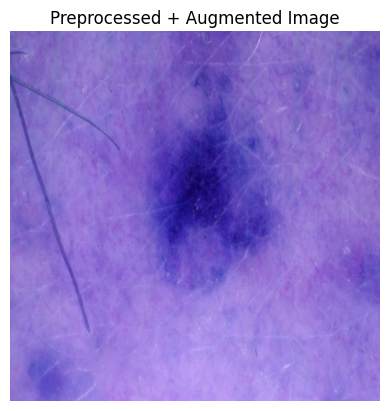

In [8]:
show_image(train_paths)

In [ ]:
from tensorflow.keras import layers, models
import tensorflow as tf

def squeeze_excitation_block(input_tensor, ratio=16):
    filters = input_tensor.shape[-1]
    
    se = layers.GlobalAveragePooling2D()(input_tensor)
    se = layers.Dense(filters // ratio, activation="relu")(se)
    se = layers.Dense(filters, activation="sigmoid")(se)
    se = layers.Reshape((1, 1, filters))(se)
    
    return layers.Multiply()([input_tensor, se])

def build_model():
    base_model = tf.keras.applications.EfficientNetV2S(
        include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3)
    )
    
    base_model.trainable = True
    for layer in base_model.layers[:int(len(base_model.layers) * 0.7)]:
        layer.trainable = False

    inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
    x = base_model(inputs, training=False)

    x = squeeze_excitation_block(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(2048, activation="mish")(x)
    x = layers.Dropout(0.4)(x)
    x = layers.LayerNormalization()(x)

    x = layers.Dense(1024, activation="mish")(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Dense(512, activation="mish")(x)
    x = layers.Dropout(0.2)(x)

    outputs = layers.Dense(len(LABELS), activation="softmax")(x)

    model = models.Model(inputs, outputs)
    optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4)

    model.compile(
        optimizer=optimizer,
        loss="categorical_crossentropy",
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc"),
                 tf.keras.metrics.Precision(name="precision"),
                 tf.keras.metrics.Recall(name="recall")]
    )

    return model
model = build_model()

In [10]:
train_labels_argmax = np.argmax(train_labels, axis=1)
class_weights = compute_class_weight(class_weight="balanced", classes=np.arange(len(LABELS)), y=train_labels_argmax)
class_weights_dict = {i: weight for i, weight in enumerate(class_weights)}

In [ ]:
model.summary()

In [ ]:
checkpoint = ModelCheckpoint(f"{MODEL_NAME}_baserun.keras", monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", 
                                                    factor=0.5, 
                                                    patience=3, 
                                                    min_lr=1e-6, 
                                                    verbose=1)
                                                    
history = model.fit(train_dataset, validation_data=val_dataset, epochs=EPOCHS, callbacks=[checkpoint, lr_scheduler],
                    class_weight=class_weights_dict)

Epoch 1/20


In [32]:
checkpoint = ModelCheckpoint(f"{MODEL_NAME}_baserun_2.keras", monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", 
                                                    factor=0.5, 
                                                    patience=3, 
                                                    min_lr=1e-6, 
                                                    verbose=1)
                                                    
history2 = model.fit(train_dataset, validation_data=val_dataset, epochs=EPOCHS, callbacks=[checkpoint, lr_scheduler],
                    class_weight=class_weights_dict)

Epoch 1/20
424/519 ━━━━━━━━━━━━━━━━━━━━ 2:19 1s/step - accuracy: 0.8093 - auc: 0.9820 - loss: 0.2905 - precision: 0.8333 - recall: 0.7898

KeyboardInterrupt: 

### Soft masking

In [ ]:
BACKGROUND_FADE = 0.3
def create_mask_from_polygon(polygon, height, width):
    polygon = np.array(polygon, dtype=np.int32).reshape((-1, 2))
    mask = np.zeros((height, width), dtype=np.uint8)
    cv2.fillPoly(mask, [polygon], color=1)
    return mask

def soft_mask(path_str):
    import numpy as np
    import cv2
    import os

    path_str = path_str.numpy().decode()
    img = cv2.imread(path_str)
    if img is None:
        raise ValueError(f"Could not read image at {path_str}")
    h, w = img.shape[:2]

    segm_path = os.path.join(SEGM_DIR, os.path.basename(path_str).split('.')[0] + '.txt')

    if not os.path.exists(segm_path):
        return img.astype(np.uint8)

    with open(segm_path, 'r') as f:
        parts = list(map(float, f.read().strip().split()))
    if len(parts) < 3:
        return img.astype(np.uint8)
    
    polygon_normalized = parts[1:]  # skip class id

    if len(polygon_normalized) % 2 != 0:
        polygon_normalized = polygon_normalized[:-1]  # remove last

    polygon = [(int(polygon_normalized[i] * w), int(polygon_normalized[i + 1] * h)) 
               for i in range(0, len(polygon_normalized), 2)]

    mask = create_mask_from_polygon(polygon, h, w)  # binary 0/1
    mask_3c = np.stack([mask]*3, axis=-1).astype(np.float32)

    background_fade = BACKGROUND_FADE
    blended = (img * mask_3c + img * (1 - mask_3c) * background_fade).astype(np.uint8)
    return blended



def segment(file_path, label):
    img = tf.py_function(soft_mask, [file_path], tf.uint8)
    img.set_shape([None, None, 3])

    img = tf.image.resize(img, IMG_SIZE)
    img = tf.keras.applications.efficientnet.preprocess_input(img)

    return img, label


def preprocess_and_augment(file_path, label):
    img, label = segment(file_path, label)

    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    img = tf.image.random_brightness(img, max_delta=0.2)
    img = tf.image.random_contrast(img, lower=0.8, upper=1.2)

    return img, label

In [14]:
train_dataset = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
train_dataset = train_dataset.map(preprocess_and_augment).shuffle(512).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_dataset = tf.data.Dataset.from_tensor_slices((val_paths, val_labels))
val_dataset = val_dataset.map(segment).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_dataset = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
test_dataset = test_dataset.map(segment).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [1]:
import os
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf

for path in train_paths:
    base_filename = os.path.basename(path).split('.')[0]
    segm_path = os.path.join(SEGM_DIR, base_filename + '.txt')

    if os.path.exists(segm_path):
        print("Found matching image and segmentation file:")
        print("Image path:", path)
        print("Segmentation path:", segm_path)

        path_tensor = tf.convert_to_tensor(path, dtype=tf.string)
        dummy_label = tf.constant(0)

        processed_img_tensor, _ = preprocess_and_augment(path_tensor, dummy_label)

        processed_img = processed_img_tensor.numpy()
        processed_img = (processed_img - processed_img.min()) / (processed_img.max() - processed_img.min())

        plt.imshow(processed_img)
        plt.title("Preprocessed + Augmented Image")
        plt.axis("off")
        plt.show()
        break
else:
    print("No matching image and segmentation file found.")


NameError: name 'train_paths' is not defined

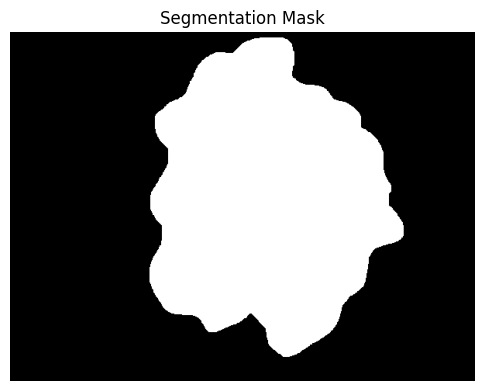

In [16]:
import tensorflow as tf
import matplotlib.pyplot as plt
import os
zip = __builtins__.zip 
# Example: take one image file from the segmentations folder
image_path = "/Users/mac/Development/diploma/skin-mutation-detection/unified_dataset/images/ISIC_0024306.jpg"
segm_path = os.path.join(SEGM_DIR, os.path.basename(image_path).split('.')[0]+'.txt')

# Load image to get dimensions
image = cv2.imread(image_path)
if image is None:
    raise ValueError(f"Could not read image {image_path}")
h, w = image.shape[:2]

# Create empty mask
mask = np.zeros((h, w), dtype=np.uint8)

# Parse segmentation .txt file
if os.path.exists(segm_path):
    with open(segm_path, 'r') as f:
        for line in f:
            parts = list(map(float, line.strip().split()))  # Ensure all parts are floats
            if len(parts) < 7:
                continue  # at least 3 points
            
            class_id = int(parts[0])  # First element is the class id
            coords_normalized = parts[1:]  # Remaining are the normalized coordinates
            
            # Create points by denormalizing the coordinates
            points = [(int(x * w), int(y * h)) for x, y in zip(coords_normalized[::2], coords_normalized[1::2])]
            
            # Convert points into a polygon and fill it in the mask
            polygon = np.array(points, dtype=np.int32)
            cv2.fillPoly(mask, [polygon], color=1)

# Show the binary mask
plt.figure(figsize=(6, 6))
plt.imshow(mask, cmap='gray')
plt.title("Segmentation Mask")
plt.axis("off")
plt.show()

In [39]:
model = build_model()
checkpoint = ModelCheckpoint(f"{MODEL_NAME}_softmask_baserun_2.keras", monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", 
                                                    factor=0.5, 
                                                    patience=3, 
                                                    min_lr=1e-6, 
                                                    verbose=1)
                                                    
history2 = model.fit(train_dataset, validation_data=val_dataset, epochs=EPOCHS, callbacks=[checkpoint, lr_scheduler],
                    class_weight=class_weights_dict)

Epoch 1/20


2025-05-07 10:22:03.737125: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:450] ShuffleDatasetV3:79: Filling up shuffle buffer (this may take a while): 470 of 512
2025-05-07 10:22:04.211782: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:480] Shuffle buffer filled.


519/519 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.3757 - auc: 0.7731 - loss: 1.7857 - precision: 0.6335 - recall: 0.1381
Epoch 1: val_accuracy improved from -inf to 0.36276, saving model to efficientnetv2-s-onehot-deep-unified_softmask_baserun_2.keras
519/519 ━━━━━━━━━━━━━━━━━━━━ 945s 2s/step - accuracy: 0.3758 - auc: 0.7732 - loss: 1.7852 - precision: 0.6335 - recall: 0.1383 - val_accuracy: 0.3628 - val_auc: 0.7839 - val_loss: 1.8427 - val_precision: 0.4203 - val_recall: 0.2441 - learning_rate: 1.0000e-04
Epoch 2/20
519/519 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5370 - auc: 0.8864 - loss: 1.1920 - precision: 0.6524 - recall: 0.4154
Epoch 2: val_accuracy improved from 0.36276 to 0.38543, saving model to efficientnetv2-s-onehot-deep-unified_softmask_baserun_2.keras
519/519 ━━━━━━━━━━━━━━━━━━━━ 774s 1s/step - accuracy: 0.5370 - auc: 0.8864 - loss: 1.1919 - precision: 0.6524 - recall: 0.4155 - val_accuracy: 0.3854 - val_auc: 0.8042 - val_loss: 1.8802 - val_precision: 0.4135 - v

KeyboardInterrupt: 

In [28]:
checkpoint = ModelCheckpoint("efficientnet-v2-m-onehot-deep-split_baserun_2.keras", monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", 
                                                    factor=0.5, 
                                                    patience=3, 
                                                    min_lr=1e-6, 
                                                    verbose=1)
                                                    
history3 = model.fit(train_dataset, validation_data=val_dataset, epochs=EPOCHS, callbacks=[checkpoint, lr_scheduler],
                    class_weight=class_weights_dict)

Epoch 1/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 334ms/step - accuracy: 0.9421 - auc: 0.9978 - loss: 0.0734 - precision: 0.9478 - recall: 0.9387
Epoch 1: val_accuracy improved from -inf to 0.83853, saving model to efficientnet-v2-m-onehot-deep-split_baserun_2.keras
634/634 ━━━━━━━━━━━━━━━━━━━━ 233s 359ms/step - accuracy: 0.9421 - auc: 0.9978 - loss: 0.0734 - precision: 0.9478 - recall: 0.9387 - val_accuracy: 0.8385 - val_auc: 0.9683 - val_loss: 0.6954 - val_precision: 0.8415 - val_recall: 0.8362 - learning_rate: 1.0000e-06
Epoch 2/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 333ms/step - accuracy: 0.9399 - auc: 0.9973 - loss: 0.0809 - precision: 0.9441 - recall: 0.9372
Epoch 2: val_accuracy improved from 0.83853 to 0.84366, saving model to efficientnet-v2-m-onehot-deep-split_baserun_2.keras
634/634 ━━━━━━━━━━━━━━━━━━━━ 232s 358ms/step - accuracy: 0.9399 - auc: 0.9973 - loss: 0.0809 - precision: 0.9441 - recall: 0.9372 - val_accuracy: 0.8437 - val_auc: 0.9700 - val_loss: 0.6858 - val_precision: 0.8460 

58/80 ━━━━━━━━━━━━━━━━━━━━ 3s 166ms/step - accuracy: 0.8440 - auc: 0.9662 - loss: 0.7485 - precision: 0.8475 - recall: 0.8404

80/80 ━━━━━━━━━━━━━━━━━━━━ 23s 290ms/step - accuracy: 0.8459 - auc: 0.9671 - loss: 0.7300 - precision: 0.8493 - recall: 0.8426


2025-03-17 16:26:08.087515: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


80/80 ━━━━━━━━━━━━━━━━━━━━ 31s 278ms/step
              precision    recall  f1-score   support

         MEL       0.74      0.78      0.76       452
          NV       0.92      0.89      0.90      1288
         BCC       0.87      0.93      0.90       333
          AK       0.69      0.76      0.72        86
         BKL       0.79      0.76      0.77       263
          DF       0.75      0.75      0.75        24
        VASC       0.85      0.88      0.86        25
         SCC       0.73      0.70      0.72        63

    accuracy                           0.85      2534
   macro avg       0.79      0.81      0.80      2534
weighted avg       0.85      0.85      0.85      2534



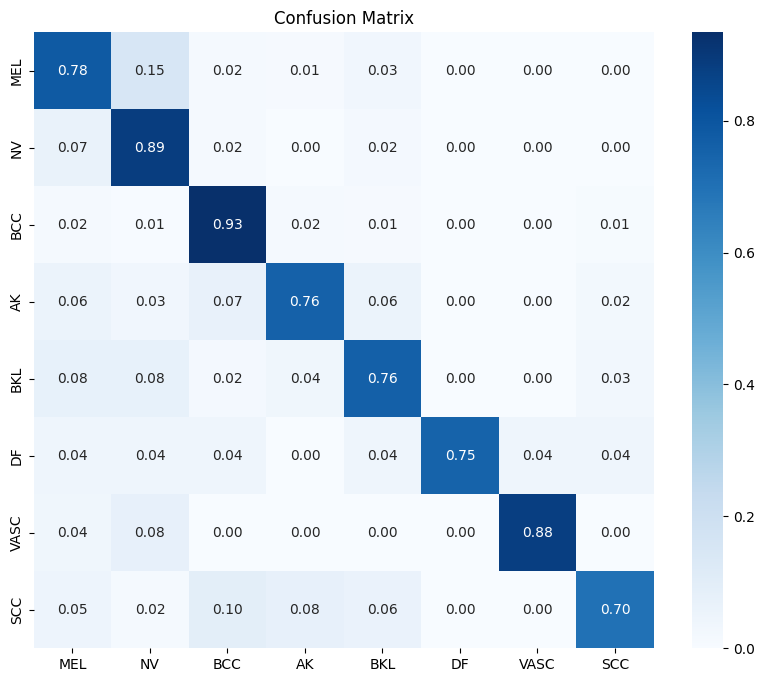

In [29]:
result = model.evaluate(test_dataset)
y_true = np.argmax(np.concatenate([y.numpy() for _, y in test_dataset]), axis=1)
y_pred = np.argmax(model.predict(test_dataset), axis=1)

print(classification_report(y_true, y_pred, target_names=LABELS))

conf_matrix = confusion_matrix(y_true, y_pred, normalize="true")
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, cmap="Blues", fmt=".2f", xticklabels=LABELS, yticklabels=LABELS)
plt.title("Confusion Matrix")
plt.show()

# Fine-tuning

In [18]:
tf.compat.v1.enable_eager_execution()
model = tf.keras.models.load_model('/teamspace/studios/this_studio/models/weights/efficientnet-v2-m-onehot_baserun.keras')

/Users/mac/Library/Caches/pypoetry/virtualenvs/diploma-JhBIondL-py3.11/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 1308 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [15]:
model.evaluate(test_dataset_2)

258/258 ━━━━━━━━━━━━━━━━━━━━ 580s 2s/step - accuracy: 0.5873 - loss: 0.8531 - precision: 0.6827 - recall: 0.5625


[0.8416513204574585,
 0.4922311305999756,
 0.5843790769577026,
 0.5039573311805725]

In [20]:
for layer in model.layers:
     if layer.name == 'efficientnetv2-m':
         layer.trainable = True
         for l in layer.layers[:-200]:
              l.trainable = False
         for l in layer.layers[-200:]:
              l.trainable = True
     if layer.name == 'batch_normalization_1':
         layer.trainable = False
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 456, 456, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-m (Functional)   │ (None, 15, 15, 1280)   │    53,150,388 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1024)           │     1,311,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │         8,200 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 162,835,126 (621.17 MB)

 Trainable params: 31,530,196 (120.28 MB)

 Non-trainable params: 22,944,232 (87.53 MB)

 Optimizer params: 108,360,698 (413.36 MB)

In [21]:
checkpoint = ModelCheckpoint("efficientnet-v2-m-onehot_finetuning.keras", monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
history = model.fit(train_dataset, validation_data=test_dataset, epochs=EPOCHS, callbacks=[checkpoint],
                    class_weight=class_weights_dict)

Epoch 1/20


792/792 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6119 - loss: 0.9054 - precision: 0.6894 - recall: 0.5100
Epoch 1: val_accuracy improved from -inf to 0.56555, saving model to efficientnet-v2-m-onehot_finetuning.keras
792/792 ━━━━━━━━━━━━━━━━━━━━ 2619s 3s/step - accuracy: 0.6118 - loss: 0.9058 - precision: 0.6894 - recall: 0.5099 - val_accuracy: 0.5656 - val_loss: 1.2173 - val_precision: 0.6631 - val_recall: 0.4442
Epoch 2/20
792/792 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6558 - loss: 0.6761 - precision: 0.7386 - recall: 0.5603
Epoch 2: val_accuracy improved from 0.56555 to 0.62566, saving model to efficientnet-v2-m-onehot_finetuning.keras
792/792 ━━━━━━━━━━━━━━━━━━━━ 2177s 3s/step - accuracy: 0.6558 - loss: 0.6764 - precision: 0.7386 - recall: 0.5603 - val_accuracy: 0.6257 - val_loss: 1.0137 - val_precision: 0.6772 - val_recall: 0.5494
Epoch 3/20
792/792 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6923 - loss: 0.5476 - precision: 0.7503 - recall: 0.6250
Epoch 3: val_accur

KeyboardInterrupt: 

In [ ]:
# checkpoint = ModelCheckpoint("efficientnet-v2-m-onehot_finetuning.keras", monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
# history = model.fit(train_dataset, validation_data=test_dataset_2, epochs=EPOCHS, callbacks=[checkpoint],
#                     class_weight=class_weights_dict)

Epoch 1/20
792/792 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7569 - loss: 0.3798 - precision: 0.7922 - recall: 0.7203
Epoch 1: val_accuracy improved from -inf to 0.50522, saving model to efficientnet-v2-m-onehot_finetuning.keras
792/792 ━━━━━━━━━━━━━━━━━━━━ 2074s 3s/step - accuracy: 0.7570 - loss: 0.3799 - precision: 0.7922 - recall: 0.7203 - val_accuracy: 0.5052 - val_loss: 0.9712 - val_precision: 0.5086 - val_recall: 0.6099
Epoch 2/20
792/792 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7700 - loss: 0.3524 - precision: 0.7983 - recall: 0.7368
Epoch 2: val_accuracy did not improve from 0.50522
792/792 ━━━━━━━━━━━━━━━━━━━━ 2025s 3s/step - accuracy: 0.7700 - loss: 0.3524 - precision: 0.7984 - recall: 0.7369 - val_accuracy: 0.4942 - val_loss: 1.1084 - val_precision: 0.4868 - val_recall: 0.5870
Epoch 3/20
792/792 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7780 - loss: 0.3390 - precision: 0.8038 - recall: 0.7458
Epoch 3: val_accuracy improved from 0.50522 to 0.51238, saving model t

In [ ]:
# model.save('efficientnet-v2-m-onehot_baserun.keras')

In [ ]:
import pandas as pd

metadata = pd.read_csv('/Users/mac/Development/diploma/skin-mutation-detection/ISIC_2020_Dataset/ISIC_2020_Train_Metadata.csv')
metadata_2019 = pd.read_csv('/Users/mac/Development/diploma/skin-mutation-detection/data/train/ISIC_2019_Training_Metadata.csv')
metadata_filtered = metadata[metadata['diagnosis'] == 'melanoma']

metadata_filtered = metadata_filtered[~metadata_filtered['image_name'].isin(metadata_2019['image'])]

print(metadata_filtered)

         image_name  patient_id   lesion_id     sex  age_approx  \
91     ISIC_0149568  IP_0962375  IL_6540984  female        55.0   
235    ISIC_0188432  IP_0135517  IL_7870569  female        50.0   
314    ISIC_0207268  IP_7735373  IL_1066532    male        55.0   
399    ISIC_0232101  IP_8349964  IL_8939481    male        65.0   
459    ISIC_0247330  IP_3232631  IL_3206110  female        65.0   
...             ...         ...         ...     ...         ...   
32969  ISIC_9955163  IP_7507212  IL_4873145    male        55.0   
33000  ISIC_9963177  IP_1165806  IL_0973502    male        70.0   
33014  ISIC_9967383  IP_7887363  IL_2267077    male        60.0   
33050  ISIC_9978107  IP_2860540  IL_8465436    male        65.0   
33117  ISIC_9998682  IP_2516168  IL_1802809    male        60.0   

      anatom_site_general_challenge diagnosis benign_malignant  target  
91                  upper extremity  melanoma        malignant       1  
235                 upper extremity  melanoma    

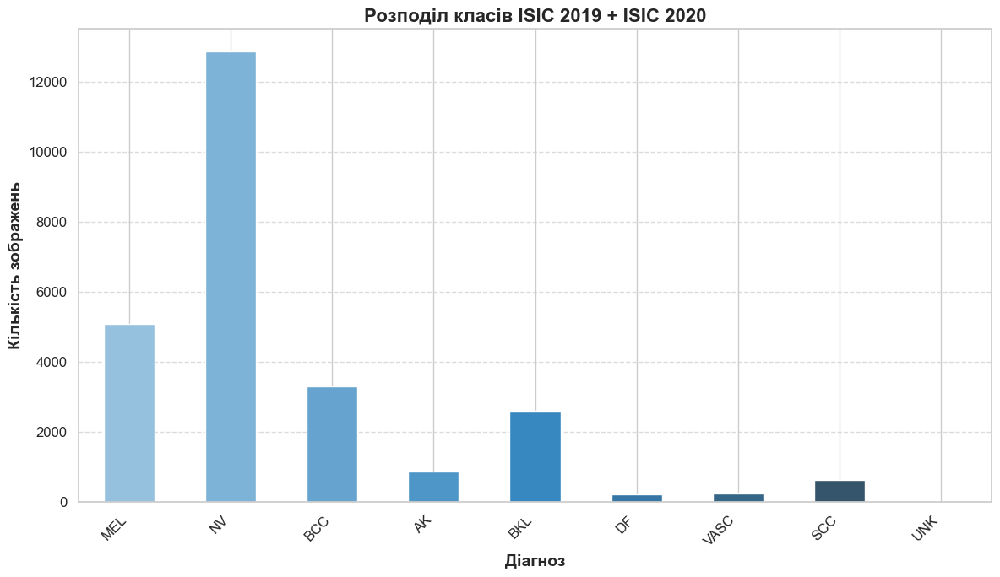

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the metadata for ISIC 2019
metadata_2019 = pd.read_csv('/Users/mac/Development/diploma/skin-mutation-detection/data/train/ISIC_2019_Training_Groundtruth.csv')

# Sum up the values for each class (ignoring the 'image' column)
class_counts = metadata_2019.drop(columns=['image']).sum()

# Add 584 to the 'MEL' class count as per your request
class_counts['MEL'] += 584

# Set a modern Seaborn style
sns.set(style="whitegrid")

# Create the plot with custom colors from Seaborn's palette
plt.figure(figsize=(12, 7))
ax = class_counts.plot(kind='bar', color=sns.color_palette("Blues_d", len(class_counts)))

# Adding a title and labels with modern fonts
plt.title('Розподіл класів ISIC 2019 + ISIC 2020', fontsize=16, fontweight='bold')
plt.xlabel('Діагноз', fontsize=14, fontweight='bold')
plt.ylabel('Кількість зображень', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=12)
plt.yticks(fontsize=12)

# Add a grid for better readability on the y-axis
plt.grid(True, axis='y', linestyle='--', alpha=0.7)

# Tight layout to make sure labels don't get cut off
plt.tight_layout()

# Show the plot
plt.show()


In [ ]:
def plot_history(history_dict):
    metrics = ['accuracy', 'loss', 'auc', 'precision', 'recall']
    
    for metric in metrics:
        if metric in history_dict:
            val_metric = f'val_{metric}'
            plt.figure(figsize=(8, 4))
            plt.plot(history_dict[metric], label=f'Train {metric}')
            if val_metric in history_dict:
                plt.plot(history_dict[val_metric], label=f'Validation {metric}')
            plt.title(f'{metric.capitalize()} Over Epochs')
            plt.xlabel('Epochs')
            plt.ylabel(metric.capitalize())
            plt.legend()
            plt.grid(True)
            plt.tight_layout()
            plt.show()


In [ ]:
plot_history(history3.history)

In [9]:
## Testing models
models_paths = ["/Users/mac/Development/diploma/skin-mutation-detection/models/weights/resnet50-onehot-deep-unified_softmask_baserun_2.keras", 
                "/Users/mac/Development/diploma/skin-mutation-detection/models/weights/efficientnetv2-s-onehot-deep-unified_softmask_baserun_2.keras"]


#### (1) Using only the pre-defined lesion segmentations

In [16]:
SEGM_DIR = os.path.join(UNIFIED_DATASET_PATH, "segmentations")
test_dataset = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
test_dataset = test_dataset.map(segment).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

/Users/mac/Library/Caches/pypoetry/virtualenvs/diploma-JhBIondL-py3.11/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 296 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


81/81 ━━━━━━━━━━━━━━━━━━━━ 91s 1s/step - accuracy: 0.7314 - auc: 0.9458 - loss: 0.9560 - precision: 0.7428 - recall: 0.7197
81/81 ━━━━━━━━━━━━━━━━━━━━ 87s 977ms/step
              precision    recall  f1-score   support

         MEL       0.69      0.68      0.68       511
          NV       0.86      0.76      0.81      1288
         BCC       0.77      0.88      0.82       332
          AK       0.57      0.57      0.57        86
         BKL       0.53      0.63      0.58       263
          DF       0.42      0.46      0.44        24
        VASC       0.33      0.92      0.48        25
         SCC       0.49      0.65      0.56        63

    accuracy                           0.73      2592
   macro avg       0.58      0.69      0.62      2592
weighted avg       0.75      0.73      0.74      2592



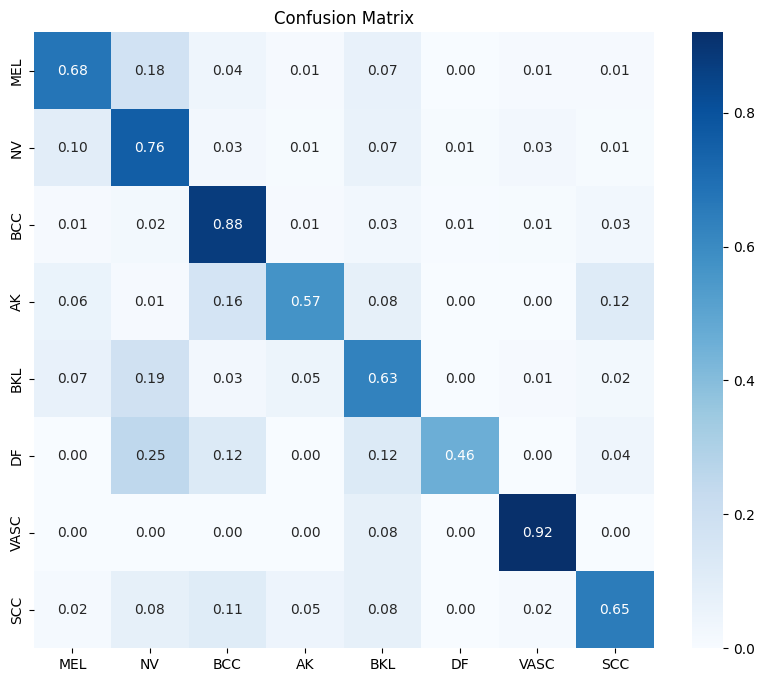

In [ ]:
tf.keras.config.enable_unsafe_deserialization()
result = model.evaluate(test_dataset)
y_true = np.argmax(np.concatenate([y.numpy() for _, y in test_dataset]), axis=1)
y_pred = np.argmax(model.predict(test_dataset), axis=1)

print(classification_report(y_true, y_pred, target_names=LABELS))

conf_matrix = confusion_matrix(y_true, y_pred, normalize="true")
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, cmap="Blues", fmt=".2f", xticklabels=LABELS, yticklabels=LABELS)
plt.title("Confusion Matrix")
plt.show()


#### (2) Using YOLO model to segment, and feed afterwards

In [105]:
import os
import cv2
import numpy as np
from ultralytics import YOLO
import tensorflow as tf

# Define temp directory for saving YOLO formatted txt files
TEMP_DIR = "temp_segmentation_files2"
os.makedirs(TEMP_DIR, exist_ok=True)

# Load the YOLO model for segmentation
yolo_model = YOLO("/Users/mac/Development/diploma/skin-mutation-detection/models/weights/yolo-isic-segm.pt")  # Use your custom model if needed

def save_yolo_format(segmentation_result, output_path, img_width, img_height):
    """
    Save segmentation result to YOLO format (polygon coordinates).
    """
    with open(output_path, 'w') as f:
        class_id = segmentation_result['class_id']
        polygon = segmentation_result['polygon']  # Assumed to be a list of (x, y) pairs
            
        # Normalize the coordinates to YOLO format
        normalized_polygon = []
        for (x, y) in polygon:
            normalized_polygon.append(x / img_width)
            normalized_polygon.append(y / img_height)
        
        # Write in the YOLO format: class_id and normalized (x, y) coordinates
        f.write(f"{class_id} " + " ".join(map(str, normalized_polygon)) + "\n")

def perform_yolo_segmentation(image_path, output_txt_path):
    """
    Perform segmentation on the input image and save the result in YOLO format.
    """
    # Load the image and get its dimensions
    img = cv2.imread(image_path)
    img_height, img_width = img.shape[:2]

    results = yolo_model.predict(image_path, iou=0.6, conf=0.2) 
    
    if results[0].masks is not None:  # Check if masks are available
        most_probable_mask = None
        highest_confidence = -1  # Initialize to an impossible low confidence

        for idx, result in enumerate(results[0].masks):  # Loop over each mask (segmentation)
            confidence = results[0].boxes[idx].conf  # Confidence score of the detection

            if confidence > highest_confidence:
                highest_confidence = confidence
                most_probable_mask = result  # Update with the most probable mask

        if most_probable_mask is not None:
            class_id = int(results[0].boxes[idx].cls)  # Get class ID from bounding box
            polygon = most_probable_mask.xy[0].tolist()  # Get polygon points from mask result

            segmentation_result = {
                'class_id': class_id,
                'polygon': polygon
            }

            # Save the segmentation result to YOLO format
            save_yolo_format(segmentation_result, output_txt_path, img_width, img_height)

def segment_and_save(image_path):
    """
    Perform segmentation on a single image and save the result in YOLO format.
    """
    output_txt_path = os.path.join(TEMP_DIR, os.path.basename(image_path).replace('.jpg', '.txt'))
    perform_yolo_segmentation(image_path, output_txt_path)

# Iterate over the test_dataset and apply segmentation
for image_path, _ in test_dataset:
    image_path = image_path.numpy().decode()  # Convert TensorFlow EagerTensor to string
    segment_and_save(image_path)



image 1/1 /Users/mac/Development/diploma/skin-mutation-detection/unified_dataset/images/ISIC_0065467.jpg: 640x640 1 NV, 211.9ms
Speed: 3.1ms preprocess, 211.9ms inference, 9.6ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /Users/mac/Development/diploma/skin-mutation-detection/unified_dataset/images/ISIC_0057377.jpg: 640x640 1 NV, 1 BKL, 77.2ms
Speed: 2.0ms preprocess, 77.2ms inference, 2.7ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /Users/mac/Development/diploma/skin-mutation-detection/unified_dataset/images/ISIC_0029869.jpg: 480x640 1 NV, 67.4ms
Speed: 1.7ms preprocess, 67.4ms inference, 1.1ms postprocess per image at shape (1, 3, 480, 640)

image 1/1 /Users/mac/Development/diploma/skin-mutation-detection/unified_dataset/images/ISIC_0066491.jpg: 640x640 1 SCC, 84.4ms
Speed: 1.8ms preprocess, 84.4ms inference, 2.0ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /Users/mac/Development/diploma/skin-mutation-detection/unified_dataset/images/I

In [109]:
SEGM_DIR =  "temp_segmentation_files"
test_dataset = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
test_dataset = test_dataset.map(segment).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [24]:
metrics = model.evaluate(test_dataset)

81/81 ━━━━━━━━━━━━━━━━━━━━ 109s 1s/step - accuracy: 0.6467 - auc: 0.9099 - loss: 1.4111 - precision: 0.6602 - recall: 0.6351


In [25]:
labeled_metrics = result
yolo_metrics = metrics
labeled_metrics, yolo_metrics

([0.9764968752861023,
  0.7337962985038757,
  0.9439905881881714,
  0.745230495929718,
  0.7233796119689941],
 [1.4433308839797974,
  0.647376537322998,
  0.9069085121154785,
  0.6603773832321167,
  0.6346450448036194])

In [13]:
def plot_history(history_dict):
    metrics = ['accuracy', 'loss', 'auc', 'precision', 'recall']
    metric_labels = {
        'accuracy': 'Точність',
        'loss': 'Втрата',
        'auc': 'Площа під кривою (AUC)',
        'precision': 'Влучність',
        'recall': 'Повнота'
    }

    for metric in metrics:
        if metric in history_dict:
            val_metric = f'val_{metric}'
            plt.figure(figsize=(8, 4))
            plt.plot(history_dict[metric], label=f'Навчальний набір')
            if val_metric in history_dict:
                plt.plot(history_dict[val_metric], label=f'Валідаційний набір')
            plt.title(f'{metric_labels[metric]} за епохами')
            plt.xlabel('Епохи')
            plt.ylabel(metric_labels[metric])
            plt.legend()
            plt.grid(True)
            plt.tight_layout()
            plt.show()


In [ ]:
plot_history(history3.history)

In [14]:
def plot_history(history_dict):
    metrics = ['accuracy', 'loss', 'auc', 'precision', 'recall']
    metric_labels = {
        'accuracy': 'Accuracy',
        'loss': 'Loss',
        'auc': 'Area Under Curve (AUC)',
        'precision': 'Precision',
        'recall': 'Recall'
    }

    for metric in metrics:
        if metric in history_dict:
            val_metric = f'val_{metric}'
            plt.figure(figsize=(8, 4))
            plt.plot(history_dict[metric], label='Training Set')
            if val_metric in history_dict:
                plt.plot(history_dict[val_metric], label='Validation Set')
            plt.title(f'{metric_labels[metric]} over Epochs')
            plt.xlabel('Epochs')
            plt.ylabel(metric_labels[metric])
            plt.legend()
            plt.grid(True)
            plt.tight_layout()
            plt.show()


In [107]:
def plot_history_ukr(history_dict, output_dir, model_name, lang_code='ukr'):
    metrics = ['accuracy', 'loss', 'auc', 'precision', 'recall']
    metric_labels = {
        'accuracy': 'Точність',
        'loss': 'Втрата',
        'auc': 'Площа під кривою (AUC)',
        'precision': 'Влучність',
        'recall': 'Повнота'
    }

    os.makedirs(output_dir, exist_ok=True)

    for metric in metrics:
        if metric in history_dict:
            val_metric = f'val_{metric}'
            plt.figure(figsize=(8, 4))
            plt.plot(history_dict[metric], label='Навчальний набір')
            if val_metric in history_dict:
                plt.plot(history_dict[val_metric], label='Валідаційний набір')
            plt.title(f'{metric_labels[metric]} протягом епох')
            plt.xlabel('Епохи')
            plt.ylabel(metric_labels[metric])
            plt.legend()
            plt.grid(True)
            plt.tight_layout()

            # Generate filename and save plot
            filename = f"{model_name}-{metric}-{lang_code}.png"
            filepath = os.path.join(output_dir, filename)
            plt.savefig(filepath)
            plt.close()


In [108]:
def plot_history(history_dict, output_dir, model_name, lang_code="eng"):
    metrics = ['accuracy', 'loss', 'auc', 'precision', 'recall']
    metric_labels = {
        'accuracy': 'Accuracy',
        'loss': 'Loss',
        'auc': 'Area Under Curve (AUC)',
        'precision': 'Precision',
        'recall': 'Recall'
    }

    os.makedirs(output_dir, exist_ok=True)

    for metric in metrics:
        if metric in history_dict:
            val_metric = f'val_{metric}'
            plt.figure(figsize=(8, 4))
            plt.plot(history_dict[metric], label='Training Set')
            if val_metric in history_dict:
                plt.plot(history_dict[val_metric], label='Validation Set')
            plt.title(f'{metric_labels[metric]} over Epochs')
            plt.xlabel('Epochs')
            plt.ylabel(metric_labels[metric])
            plt.legend()
            plt.grid(True)
            plt.tight_layout()

            # Generate filename and save plot
            filename = f"{model_name}-{metric}-{lang_code}.png"
            filepath = os.path.join(output_dir, filename)
            plt.savefig(filepath)
            plt.close()


In [117]:
from tqdm import tqdm
def confusion(model, ds):
  tf.keras.config.enable_unsafe_deserialization()
  # model.load_weights(f"{MODEL_NAME}_softmask_baserun_2.keras")
  # result = model.evaluate(ds)
  # print(result)
  y_true = np.argmax(np.concatenate([y.numpy() for _, y in tqdm(ds)]), axis=1)
  y_pred = np.argmax(model.predict(ds), axis=1)

  print(classification_report(y_true, y_pred, target_names=LABELS))

  conf_matrix = confusion_matrix(y_true, y_pred, normalize="true")
  plt.figure(figsize=(10, 8))
  sns.heatmap(conf_matrix, annot=True, cmap="Blues", fmt=".2f", xticklabels=LABELS, yticklabels=LABELS)
  plt.title("Confusion Matrix")
  plt.show()

def test_model(model, history, model_name, output_dir):
  print(history)
  plot_history(history, output_dir, model_name)
  plot_history_ukr(history, output_dir, model_name)
  train_eval_dataset = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
  train_eval_dataset = train_eval_dataset.map(preprocess_and_augment).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

  for dataset, label in zip([train_eval_dataset, val_dataset, test_dataset], ['train', 'val', 'test']):
    if label == 'train':
      continue
    print(f"#####  {label}  #####")
    confusion(model, dataset)


## Softmask Results
#### BACKGROUND_DIM = 0.65

In [110]:
model = build_model()
model.load_weights("/Users/mac/Development/diploma/skin-mutation-detection/models/weights/efficientnetv2-s-onehot-deep-unified_softmask_65_baserun_2.keras")

/Users/mac/Library/Caches/pypoetry/virtualenvs/diploma-JhBIondL-py3.11/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 296 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [111]:
import json
TRAIN_RESULT_PATH = "/Users/mac/Development/diploma/skin-mutation-detection/models/results/efficientnetv2-s-segm-65-40.json"

with open(TRAIN_RESULT_PATH) as f:
    history = json.loads(f.read())

In [112]:
BACKGROUND_FADE = 0.65

In [118]:
test_model(model, history, 'efficientnetv2-s-segm-65', "/Users/mac/Development/diploma/skin-mutation-detection/models/results/efficientnetv2-s-segm-65")

{'accuracy': [0.4139, 0.5679, 0.6177, 0.6569, 0.6873, 0.7121, 0.7271, 0.7527, 0.7663, 0.7851, 0.8015, 0.8085, 0.8157, 0.8287, 0.8395, 0.8483, 0.8535, 0.8591, 0.8634, 0.8713, 0.8674, 0.868, 0.8851, 0.8913, 0.8822, 0.898, 0.9047, 0.9047, 0.9097, 0.928, 0.9299, 0.9318, 0.9369, 0.9398, 0.9421, 0.9443, 0.9436, 0.9427, 0.9468, 0.9466], 'auc': [0.8093, 0.903, 0.9267, 0.9413, 0.9501, 0.9584, 0.9616, 0.9679, 0.9711, 0.9758, 0.9787, 0.9801, 0.9811, 0.9832, 0.9856, 0.9862, 0.9867, 0.9876, 0.9883, 0.9893, 0.9891, 0.9892, 0.9918, 0.9927, 0.9905, 0.9942, 0.9941, 0.9941, 0.9937, 0.9958, 0.9956, 0.9961, 0.9966, 0.9968, 0.9974, 0.9976, 0.9977, 0.9972, 0.998, 0.9979], 'loss': [1.5549, 1.082, 0.8856, 0.7599, 0.6622, 0.5924, 0.5525, 0.4648, 0.43, 0.3784, 0.3422, 0.3301, 0.3274, 0.3016, 0.2782, 0.2569, 0.2482, 0.2451, 0.2361, 0.2144, 0.2209, 0.1998, 0.1806, 0.1912, 0.2016, 0.1566, 0.162, 0.1656, 0.1509, 0.1199, 0.1059, 0.0945, 0.0988, 0.0943, 0.0875, 0.0811, 0.0796, 0.0825, 0.0724, 0.0848], 'precision': [0

100%|██████████| 81/81 [00:27<00:00,  2.94it/s]


80/81 ━━━━━━━━━━━━━━━━━━━━ 0s 969ms/step

2025-05-22 15:14:33.495795: W tensorflow/core/framework/op_kernel.cc:1841] OP_REQUIRES failed at xla_ops.cc:794 : NOT_FOUND: could not find registered platform with id: 0x106e8e4a0
2025-05-22 15:14:33.495892: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 16542171268934907688
2025-05-22 15:14:33.495919: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 14746523899781874040
2025-05-22 15:14:33.495971: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 8345889675509977531
2025-05-22 15:14:33.495986: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 5499993802925689675
2025-05-22 15:14:33.496026: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 15669514534922397545
2025-05-22 15:14:33.496137: I tensorflow/core/framework/local_rendezvou

NotFoundError: Graph execution error:

Detected at node cluster_0_1/xla_compile defined at (most recent call last):
<stack traces unavailable>
Detected at node cluster_0_1/xla_compile defined at (most recent call last):
<stack traces unavailable>
2 root error(s) found.
  (0) NOT_FOUND:  could not find registered platform with id: 0x106e8e4a0
	 [[{{node cluster_0_1/xla_compile}}]]
	 [[functional_38_1/dense_230_1/BiasAdd/_12]]
  (1) NOT_FOUND:  could not find registered platform with id: 0x106e8e4a0
	 [[{{node cluster_0_1/xla_compile}}]]
0 successful operations.
0 derived errors ignored. [Op:__inference_one_step_on_data_distributed_528699]

In [29]:
model = build_model()
model.load_weights("/Users/mac/Development/diploma/skin-mutation-detection/models/weights/efficientnetv2-s-onehot-deep-unified_softmask_15_baserun_2.keras")

/Users/mac/Library/Caches/pypoetry/virtualenvs/diploma-JhBIondL-py3.11/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 296 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [31]:
import json
TRAIN_RESULT_PATH = "/Users/mac/Development/diploma/skin-mutation-detection/models/results/efficientnetv2-s-segm-15-40.json"

with open(TRAIN_RESULT_PATH) as f:
    history = json.loads(f.read())

In [32]:
BACKGROUND_FADE = 0.15

{'accuracy': [0.4207, 0.5603, 0.6163, 0.6516, 0.6792, 0.7051, 0.7257, 0.7477, 0.7614, 0.7793, 0.7912, 0.8046, 0.808, 0.8149, 0.8394, 0.8493, 0.8567, 0.863, 0.8707, 0.877, 0.8651, 0.8716, 0.871, 0.8831, 0.8908, 0.8978, 0.9064, 0.9052, 0.9104, 0.92, 0.9165, 0.9181, 0.9279, 0.9235, 0.9317, 0.9275, 0.9366, 0.9345, 0.9333, 0.9323], 'auc': [0.8145, 0.9001, 0.9265, 0.9391, 0.9471, 0.956, 0.9608, 0.9668, 0.9697, 0.9738, 0.9759, 0.9789, 0.9793, 0.981, 0.9856, 0.9873, 0.9882, 0.9888, 0.99, 0.9906, 0.9889, 0.9898, 0.9901, 0.9912, 0.9922, 0.9936, 0.9938, 0.9937, 0.9948, 0.9956, 0.9958, 0.9957, 0.9963, 0.996, 0.9963, 0.9967, 0.9972, 0.9973, 0.9968, 0.9967], 'loss': [1.5627, 1.082, 0.8831, 0.7637, 0.6731, 0.6139, 0.5576, 0.4888, 0.4498, 0.4176, 0.3735, 0.3561, 0.3419, 0.3089, 0.2569, 0.2371, 0.2178, 0.2148, 0.1935, 0.1862, 0.2296, 0.2234, 0.2256, 0.1874, 0.1822, 0.1571, 0.1462, 0.1823, 0.1534, 0.115, 0.1134, 0.1109, 0.101, 0.1066, 0.0967, 0.0971, 0.0958, 0.0896, 0.0976, 0.0902], 'precision': [0.6584

100%|██████████| 648/648 [04:16<00:00,  2.52it/s]


648/648 ━━━━━━━━━━━━━━━━━━━━ 684s 1s/step
              precision    recall  f1-score   support

         MEL       0.87      0.93      0.90      4085
          NV       0.98      0.90      0.94     10300
         BCC       0.91      0.98      0.94      2659
          AK       0.87      1.00      0.93       694
         BKL       0.92      0.98      0.95      2099
          DF       0.91      1.00      0.95       191
        VASC       0.88      1.00      0.94       202
         SCC       0.91      1.00      0.95       502

    accuracy                           0.93     20732
   macro avg       0.91      0.97      0.94     20732
weighted avg       0.94      0.93      0.93     20732



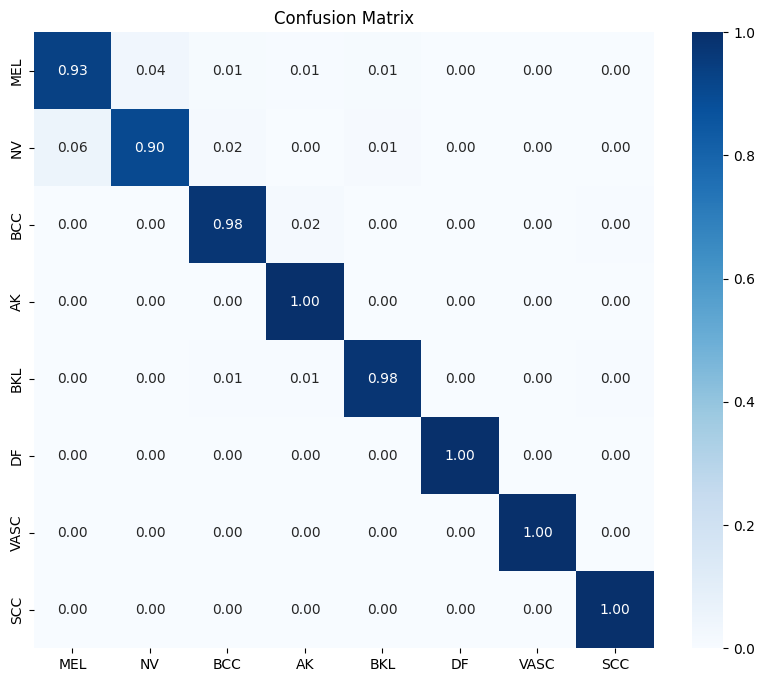

#####  val  #####


100%|██████████| 81/81 [00:30<00:00,  2.62it/s]


81/81 ━━━━━━━━━━━━━━━━━━━━ 85s 1s/step 
              precision    recall  f1-score   support

         MEL       0.71      0.76      0.73       510
          NV       0.91      0.85      0.88      1287
         BCC       0.84      0.87      0.86       332
          AK       0.60      0.74      0.66        87
         BKL       0.68      0.71      0.69       262
          DF       0.56      0.75      0.64        24
        VASC       0.70      0.81      0.75        26
         SCC       0.66      0.75      0.70        63

    accuracy                           0.81      2591
   macro avg       0.71      0.78      0.74      2591
weighted avg       0.82      0.81      0.81      2591



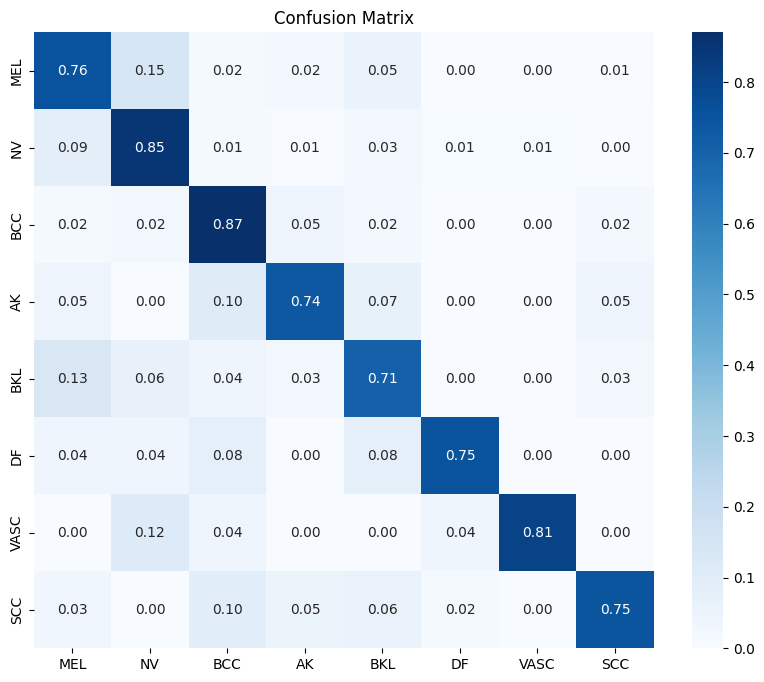

#####  test  #####


100%|██████████| 81/81 [00:27<00:00,  2.97it/s]


81/81 ━━━━━━━━━━━━━━━━━━━━ 80s 974ms/step
              precision    recall  f1-score   support

         MEL       0.73      0.76      0.74       511
          NV       0.91      0.84      0.88      1288
         BCC       0.83      0.89      0.86       332
          AK       0.62      0.65      0.64        86
         BKL       0.71      0.72      0.72       263
          DF       0.56      0.92      0.70        24
        VASC       0.64      0.92      0.75        25
         SCC       0.68      0.83      0.74        63

    accuracy                           0.82      2592
   macro avg       0.71      0.82      0.75      2592
weighted avg       0.82      0.82      0.82      2592



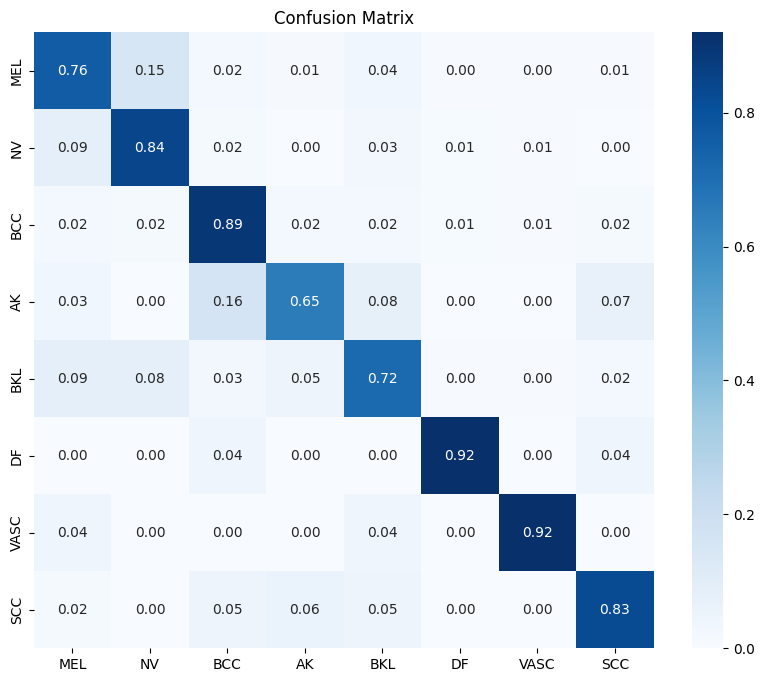

In [33]:
test_model(model, history, 'efficientnetv2-s-segm-15', "/Users/mac/Development/diploma/skin-mutation-detection/models/results/efficientnetv2-s-segm-15")

### EfficientNetV2-S NO SEGMENTATION 40 EPOCHS

In [66]:
model = build_model()
model.load_weights("/Users/mac/Development/diploma/skin-mutation-detection/models/weights/efficientnet-v2-m-onehot-deep-split_baserun_2.keras")

/Users/mac/Library/Caches/pypoetry/virtualenvs/diploma-JhBIondL-py3.11/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 296 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [69]:
def load_image(file_path, label):
    img = tf.io.read_file(file_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.keras.applications.efficientnet.preprocess_input(img)
    return img, label

def preprocess_and_augment(file_path, label):
    img, label = load_image(file_path, label)
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    img = tf.image.random_brightness(img, max_delta=0.2)
    img = tf.image.random_contrast(img, lower=0.8, upper=1.2)
    return img, label

train_dataset = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
train_dataset = train_dataset.map(preprocess_and_augment).shuffle(512).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_dataset = tf.data.Dataset.from_tensor_slices((val_paths, val_labels))
val_dataset = val_dataset.map(load_image).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_dataset = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
test_dataset = test_dataset.map(load_image).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test2_dataset = tf.data.Dataset.from_tensor_slices((test_paths_2, test_labels_2))
test2_dataset = test2_dataset.map(load_image).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


In [35]:
import json
TRAIN_RESULT_PATH = "/Users/mac/Development/diploma/skin-mutation-detection/models/results/efficientnetv2-s-no-segm-40.json"

with open(TRAIN_RESULT_PATH) as f:
    history = json.loads(f.read())

{'accuracy': [0.4587, 0.5713, 0.6424, 0.6541, 0.7046, 0.7213, 0.7428, 0.7477, 0.7776, 0.7927, 0.8052, 0.8273, 0.8467, 0.847, 0.8574, 0.8694, 0.8778, 0.8751, 0.8835, 0.8849, 0.9015, 0.908, 0.9127, 0.9129, 0.9225, 0.9302, 0.9254, 0.9287, 0.9336, 0.932, 0.9338, 0.9397, 0.9362, 0.9382, 0.9382, 0.9384, 0.9361, 0.9396, 0.9397, 0.9408], 'auc': [0.8453, 0.9074, 0.9342, 0.9393, 0.9533, 0.9595, 0.9653, 0.9662, 0.9727, 0.9765, 0.9781, 0.9831, 0.9866, 0.9862, 0.9883, 0.9891, 0.9901, 0.9906, 0.9922, 0.9913, 0.994, 0.994, 0.9946, 0.995, 0.9957, 0.9961, 0.9958, 0.9965, 0.9963, 0.997, 0.9969, 0.9972, 0.9971, 0.9967, 0.9972, 0.9973, 0.9972, 0.9971, 0.9974, 0.9975], 'loss': [1.399, 0.9981, 0.8065, 0.7296, 0.6398, 0.5629, 0.5002, 0.4697, 0.4011, 0.3617, 0.3554, 0.2978, 0.2371, 0.238, 0.2219, 0.2018, 0.1929, 0.1911, 0.1805, 0.1683, 0.1371, 0.1328, 0.1262, 0.1204, 0.1056, 0.0951, 0.099, 0.0929, 0.0927, 0.0859, 0.0849, 0.0837, 0.086, 0.0983, 0.08, 0.0822, 0.0822, 0.0783, 0.0775, 0.0806], 'precision': [0.602

100%|██████████| 648/648 [03:19<00:00,  3.25it/s]


648/648 ━━━━━━━━━━━━━━━━━━━━ 442s 662ms/step
              precision    recall  f1-score   support

         MEL       0.94      0.90      0.92      4085
          NV       0.97      0.97      0.97     10300
         BCC       0.98      1.00      0.99      2659
          AK       0.98      1.00      0.99       694
         BKL       0.95      1.00      0.98      2099
          DF       0.93      1.00      0.96       191
        VASC       0.98      1.00      0.99       202
         SCC       0.98      1.00      0.99       502

    accuracy                           0.96     20732
   macro avg       0.96      0.98      0.97     20732
weighted avg       0.96      0.96      0.96     20732



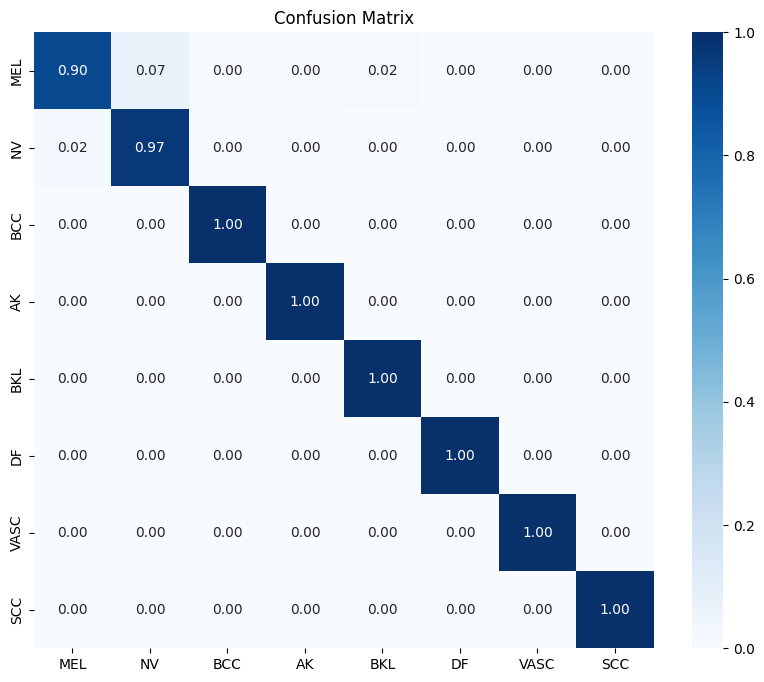

#####  val  #####


100%|██████████| 81/81 [00:03<00:00, 22.31it/s]


81/81 ━━━━━━━━━━━━━━━━━━━━ 59s 718ms/step
              precision    recall  f1-score   support

         MEL       0.76      0.77      0.76       510
          NV       0.91      0.88      0.90      1287
         BCC       0.89      0.93      0.91       332
          AK       0.77      0.76      0.76        87
         BKL       0.76      0.76      0.76       262
          DF       0.57      0.67      0.62        24
        VASC       0.88      0.88      0.88        26
         SCC       0.72      0.68      0.70        63

    accuracy                           0.84      2591
   macro avg       0.78      0.79      0.79      2591
weighted avg       0.85      0.84      0.85      2591



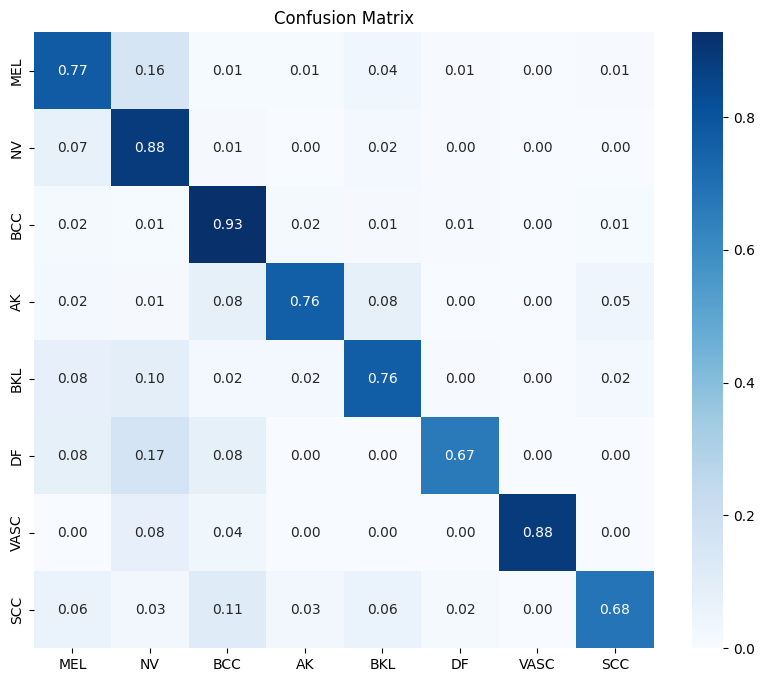

#####  test  #####


100%|██████████| 81/81 [00:03<00:00, 26.70it/s]


81/81 ━━━━━━━━━━━━━━━━━━━━ 54s 656ms/step
              precision    recall  f1-score   support

         MEL       0.76      0.79      0.78       511
          NV       0.91      0.89      0.90      1288
         BCC       0.85      0.92      0.89       332
          AK       0.73      0.67      0.70        86
         BKL       0.82      0.79      0.81       263
          DF       0.74      0.83      0.78        24
        VASC       0.85      0.92      0.88        25
         SCC       0.78      0.75      0.76        63

    accuracy                           0.85      2592
   macro avg       0.81      0.82      0.81      2592
weighted avg       0.85      0.85      0.85      2592



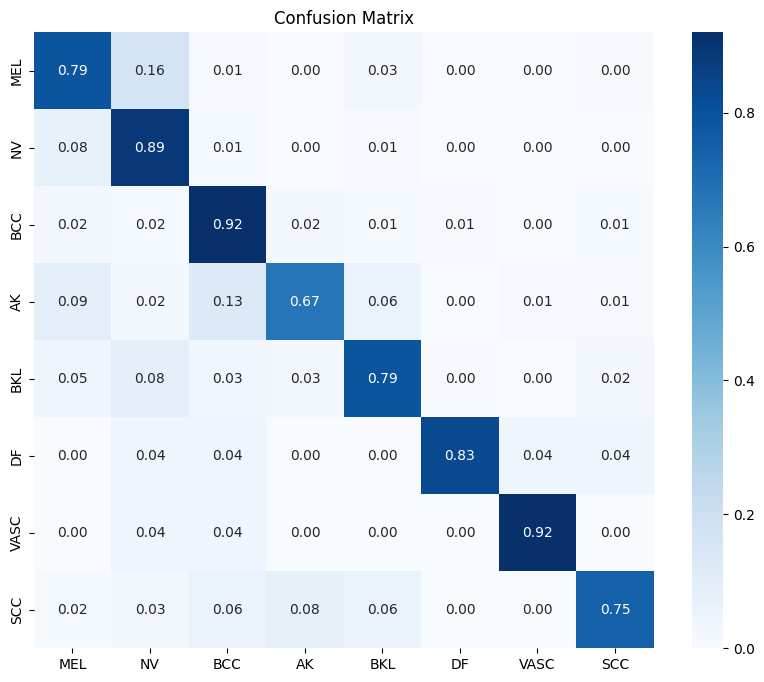

In [37]:
test_model(model, history, 'efficientnetv2-s-no-segm-40', "/Users/mac/Development/diploma/skin-mutation-detection/models/results/efficientnetv2-s-no-segm-40")

100%|██████████| 313/313 [00:07<00:00, 42.86it/s]


313/313 ━━━━━━━━━━━━━━━━━━━━ 236s 700ms/step
              precision    recall  f1-score   support

         MEL       0.86      0.93      0.89      1113
          NV       0.99      0.97      0.98      6705
         BCC       0.95      0.97      0.96       514
          AK       0.95      0.38      0.54       327
         BKL       0.95      0.95      0.95      1099
          DF       0.95      0.92      0.94       115
        VASC       0.96      0.99      0.98       142
         SCC       0.00      0.00      0.00         0

    accuracy                           0.95     10015
   macro avg       0.83      0.76      0.78     10015
weighted avg       0.96      0.95      0.95     10015



/Users/mac/Library/Caches/pypoetry/virtualenvs/diploma-JhBIondL-py3.11/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/mac/Library/Caches/pypoetry/virtualenvs/diploma-JhBIondL-py3.11/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/mac/Library/Caches/pypoetry/virtualenvs/diploma-JhBIondL-py3.11/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` pa

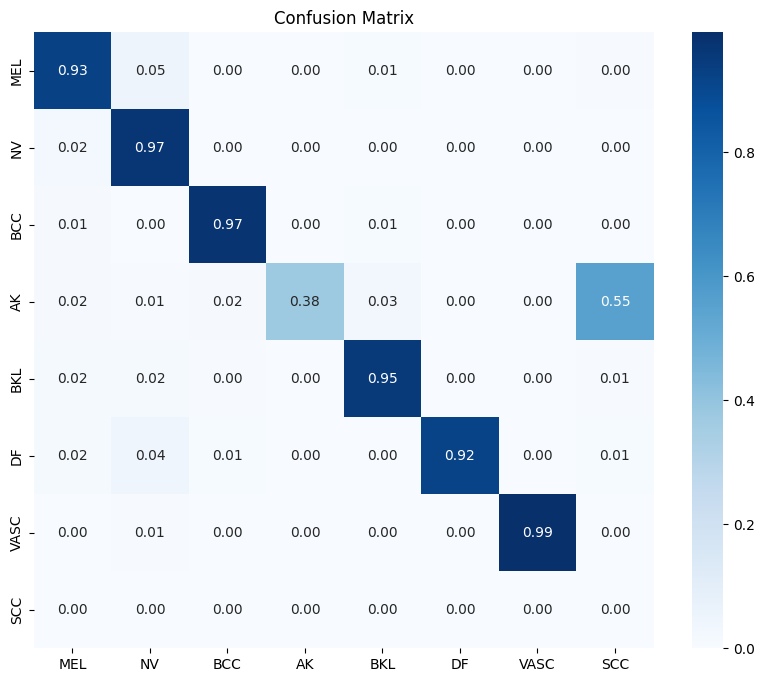

In [68]:
confusion(model, test2_dataset)

#### EfficientNetV2-S YOLO SEGM (BACKGROUND_FADE = 0.15)

In [ ]:
def preprocess_and_augment(file_path, label):
    # Apply the Python function
    img, label = segment(file_path, label)

    # Augmentation
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    img = tf.image.random_brightness(img, max_delta=0.2)
    img = tf.image.random_contrast(img, lower=0.8, upper=1.2)

    return img, label

In [45]:
SEGM_DIR =  "temp_segmentation_files"

train_dataset = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
train_dataset = train_dataset.map(preprocess_and_augment).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_dataset = tf.data.Dataset.from_tensor_slices((val_paths, val_labels))
val_dataset = val_dataset.map(segment).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_dataset = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
test_dataset = test_dataset.map(segment).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [39]:
BACKGROUND_FADE = 0.15

In [41]:
import json
TRAIN_RESULT_PATH = "/Users/mac/Development/diploma/skin-mutation-detection/models/results/efficientnetv2-s-segm-15-40.json"

with open(TRAIN_RESULT_PATH) as f:
    history = json.loads(f.read())

In [42]:
model = build_model()
model.load_weights("/Users/mac/Development/diploma/skin-mutation-detection/models/weights/efficientnetv2-s-onehot-deep-unified_softmask_15_baserun_2.keras")

/Users/mac/Library/Caches/pypoetry/virtualenvs/diploma-JhBIondL-py3.11/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 296 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


{'accuracy': [0.4207, 0.5603, 0.6163, 0.6516, 0.6792, 0.7051, 0.7257, 0.7477, 0.7614, 0.7793, 0.7912, 0.8046, 0.808, 0.8149, 0.8394, 0.8493, 0.8567, 0.863, 0.8707, 0.877, 0.8651, 0.8716, 0.871, 0.8831, 0.8908, 0.8978, 0.9064, 0.9052, 0.9104, 0.92, 0.9165, 0.9181, 0.9279, 0.9235, 0.9317, 0.9275, 0.9366, 0.9345, 0.9333, 0.9323], 'auc': [0.8145, 0.9001, 0.9265, 0.9391, 0.9471, 0.956, 0.9608, 0.9668, 0.9697, 0.9738, 0.9759, 0.9789, 0.9793, 0.981, 0.9856, 0.9873, 0.9882, 0.9888, 0.99, 0.9906, 0.9889, 0.9898, 0.9901, 0.9912, 0.9922, 0.9936, 0.9938, 0.9937, 0.9948, 0.9956, 0.9958, 0.9957, 0.9963, 0.996, 0.9963, 0.9967, 0.9972, 0.9973, 0.9968, 0.9967], 'loss': [1.5627, 1.082, 0.8831, 0.7637, 0.6731, 0.6139, 0.5576, 0.4888, 0.4498, 0.4176, 0.3735, 0.3561, 0.3419, 0.3089, 0.2569, 0.2371, 0.2178, 0.2148, 0.1935, 0.1862, 0.2296, 0.2234, 0.2256, 0.1874, 0.1822, 0.1571, 0.1462, 0.1823, 0.1534, 0.115, 0.1134, 0.1109, 0.101, 0.1066, 0.0967, 0.0971, 0.0958, 0.0896, 0.0976, 0.0902], 'precision': [0.6584

100%|██████████| 648/648 [03:34<00:00,  3.02it/s]


648/648 ━━━━━━━━━━━━━━━━━━━━ 616s 949ms/step
              precision    recall  f1-score   support

         MEL       0.58      0.87      0.69      4085
          NV       0.92      0.73      0.82     10300
         BCC       0.86      0.93      0.90      2659
          AK       0.77      0.91      0.83       694
         BKL       0.85      0.72      0.78      2099
          DF       0.67      0.75      0.71       191
        VASC       0.71      0.92      0.80       202
         SCC       0.85      0.75      0.80       502

    accuracy                           0.79     20732
   macro avg       0.78      0.82      0.79     20732
weighted avg       0.83      0.79      0.80     20732



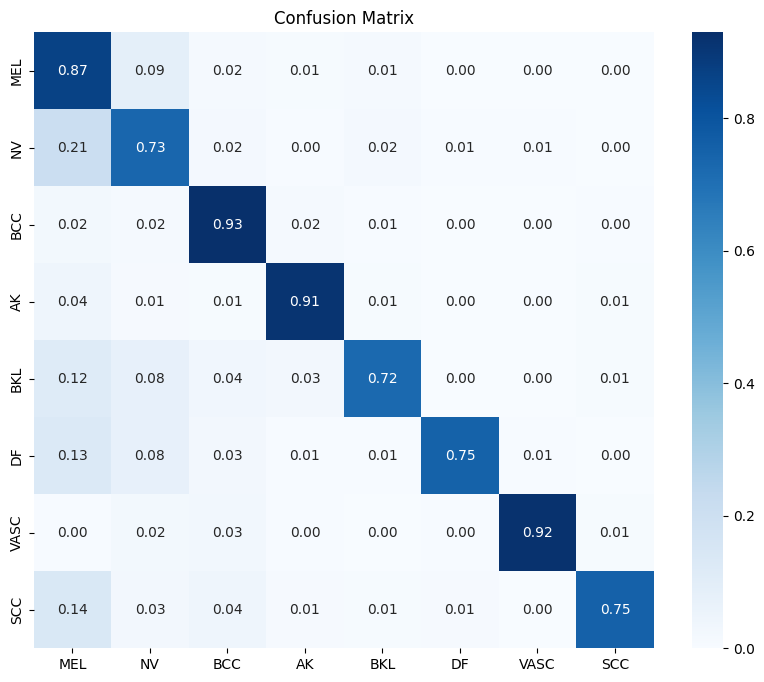

#####  val  #####


100%|██████████| 81/81 [00:24<00:00,  3.25it/s]


81/81 ━━━━━━━━━━━━━━━━━━━━ 76s 930ms/step
              precision    recall  f1-score   support

         MEL       0.48      0.73      0.58       510
          NV       0.87      0.70      0.77      1287
         BCC       0.81      0.84      0.82       332
          AK       0.56      0.71      0.63        87
         BKL       0.66      0.54      0.60       262
          DF       0.47      0.58      0.52        24
        VASC       0.62      0.81      0.70        26
         SCC       0.72      0.57      0.64        63

    accuracy                           0.70      2591
   macro avg       0.65      0.69      0.66      2591
weighted avg       0.74      0.70      0.71      2591



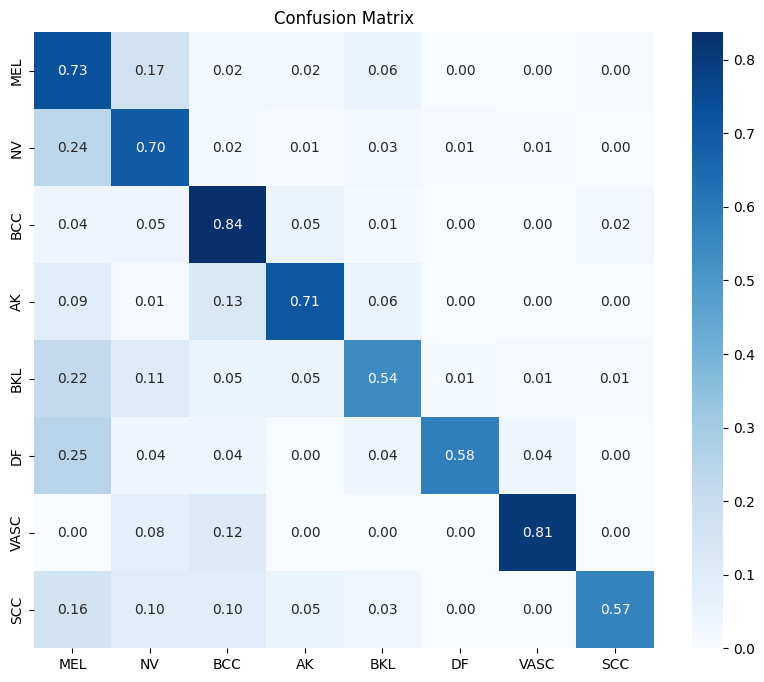

#####  test  #####


100%|██████████| 81/81 [00:53<00:00,  1.51it/s]


81/81 ━━━━━━━━━━━━━━━━━━━━ 102s 1s/step
              precision    recall  f1-score   support

         MEL       0.69      0.54      0.60       511
          NV       0.85      0.83      0.84      1288
         BCC       0.79      0.53      0.64       332
          AK       0.49      0.35      0.41        86
         BKL       0.45      0.71      0.55       263
          DF       0.45      0.75      0.56        24
        VASC       0.55      0.84      0.67        25
         SCC       0.32      0.75      0.45        63

    accuracy                           0.70      2592
   macro avg       0.57      0.66      0.59      2592
weighted avg       0.74      0.70      0.71      2592



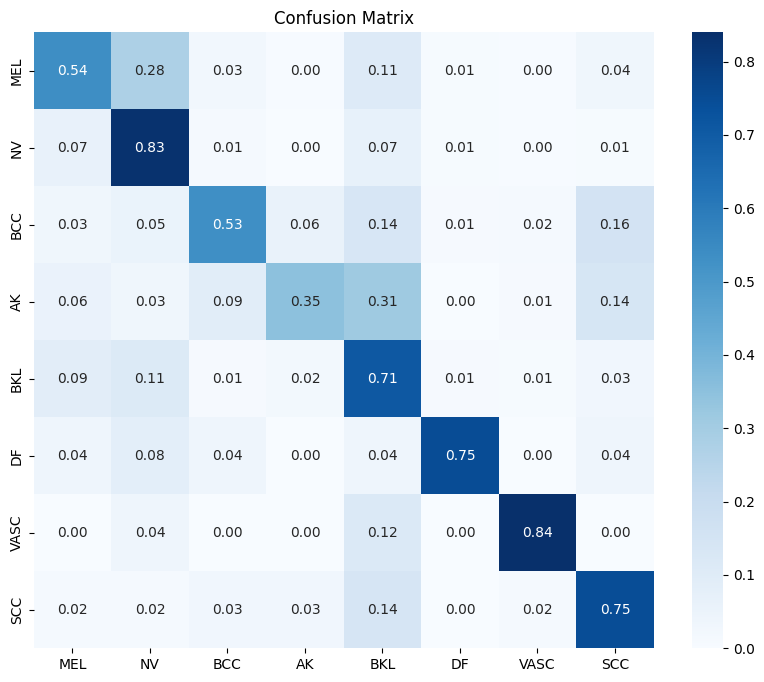

In [46]:
test_model(model, history, 'efficientnetv2-s-segm-yolo-15-40', "/Users/mac/Development/diploma/skin-mutation-detection/models/results/efficientnetv2-s-segm-yolo-15-40")

#### EfficientNetV2-S YOLO SEGM (BACKGROUND_FADE = 0.65)

In [21]:
BACKGROUND_FADE = 0.65
import json
TRAIN_RESULT_PATH = "/Users/mac/Development/diploma/skin-mutation-detection/models/results/efficientnetv2-s-segm-65-40.json"

with open(TRAIN_RESULT_PATH) as f:
    history = json.loads(f.read())


In [23]:
SEGM_DIR =  "temp_segmentation_files"

train_dataset = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
train_dataset = train_dataset.map(preprocess_and_augment).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_dataset = tf.data.Dataset.from_tensor_slices((val_paths, val_labels))
val_dataset = val_dataset.map(segment).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_dataset = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
test_dataset = test_dataset.map(segment).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

/Users/mac/Library/Caches/pypoetry/virtualenvs/diploma-JhBIondL-py3.11/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 296 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


{'accuracy': [0.4139, 0.5679, 0.6177, 0.6569, 0.6873, 0.7121, 0.7271, 0.7527, 0.7663, 0.7851, 0.8015, 0.8085, 0.8157, 0.8287, 0.8395, 0.8483, 0.8535, 0.8591, 0.8634, 0.8713, 0.8674, 0.868, 0.8851, 0.8913, 0.8822, 0.898, 0.9047, 0.9047, 0.9097, 0.928, 0.9299, 0.9318, 0.9369, 0.9398, 0.9421, 0.9443, 0.9436, 0.9427, 0.9468, 0.9466], 'auc': [0.8093, 0.903, 0.9267, 0.9413, 0.9501, 0.9584, 0.9616, 0.9679, 0.9711, 0.9758, 0.9787, 0.9801, 0.9811, 0.9832, 0.9856, 0.9862, 0.9867, 0.9876, 0.9883, 0.9893, 0.9891, 0.9892, 0.9918, 0.9927, 0.9905, 0.9942, 0.9941, 0.9941, 0.9937, 0.9958, 0.9956, 0.9961, 0.9966, 0.9968, 0.9974, 0.9976, 0.9977, 0.9972, 0.998, 0.9979], 'loss': [1.5549, 1.082, 0.8856, 0.7599, 0.6622, 0.5924, 0.5525, 0.4648, 0.43, 0.3784, 0.3422, 0.3301, 0.3274, 0.3016, 0.2782, 0.2569, 0.2482, 0.2451, 0.2361, 0.2144, 0.2209, 0.1998, 0.1806, 0.1912, 0.2016, 0.1566, 0.162, 0.1656, 0.1509, 0.1199, 0.1059, 0.0945, 0.0988, 0.0943, 0.0875, 0.0811, 0.0796, 0.0825, 0.0724, 0.0848], 'precision': [0

100%|██████████| 648/648 [05:10<00:00,  2.09it/s]


648/648 ━━━━━━━━━━━━━━━━━━━━ 1089s 2s/step
              precision    recall  f1-score   support

         MEL       0.67      0.86      0.75      4085
          NV       0.94      0.80      0.86     10300
         BCC       0.83      0.95      0.88      2659
          AK       0.81      0.93      0.87       694
         BKL       0.85      0.77      0.81      2099
          DF       0.59      0.85      0.70       191
        VASC       0.74      0.98      0.84       202
         SCC       0.93      0.74      0.82       502

    accuracy                           0.83     20732
   macro avg       0.79      0.86      0.82     20732
weighted avg       0.85      0.83      0.83     20732



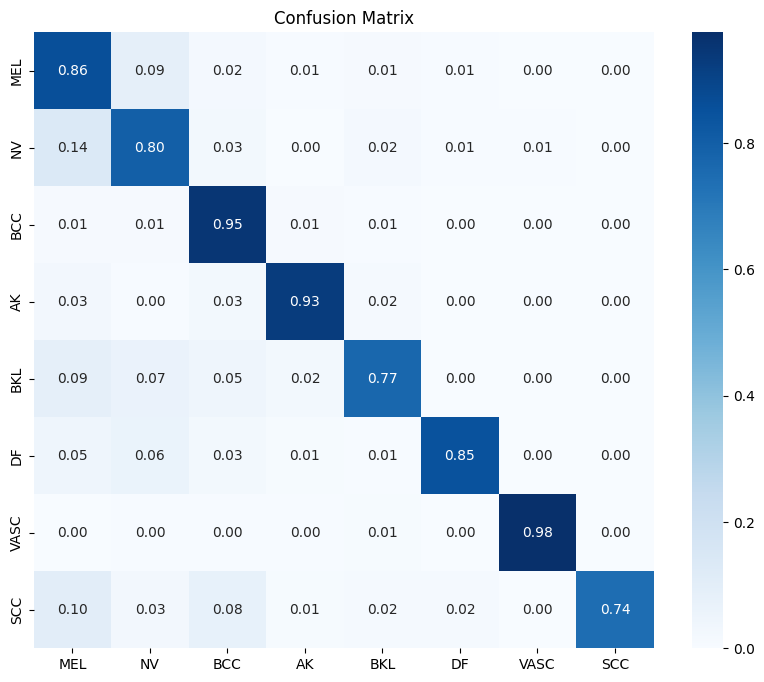

#####  val  #####


100%|██████████| 81/81 [00:39<00:00,  2.08it/s]


81/81 ━━━━━━━━━━━━━━━━━━━━ 136s 2s/step
              precision    recall  f1-score   support

         MEL       0.55      0.73      0.62       510
          NV       0.88      0.75      0.81      1287
         BCC       0.76      0.87      0.81       332
          AK       0.61      0.69      0.65        87
         BKL       0.66      0.54      0.60       262
          DF       0.39      0.58      0.47        24
        VASC       0.62      0.88      0.73        26
         SCC       0.78      0.57      0.66        63

    accuracy                           0.73      2591
   macro avg       0.66      0.70      0.67      2591
weighted avg       0.76      0.73      0.74      2591



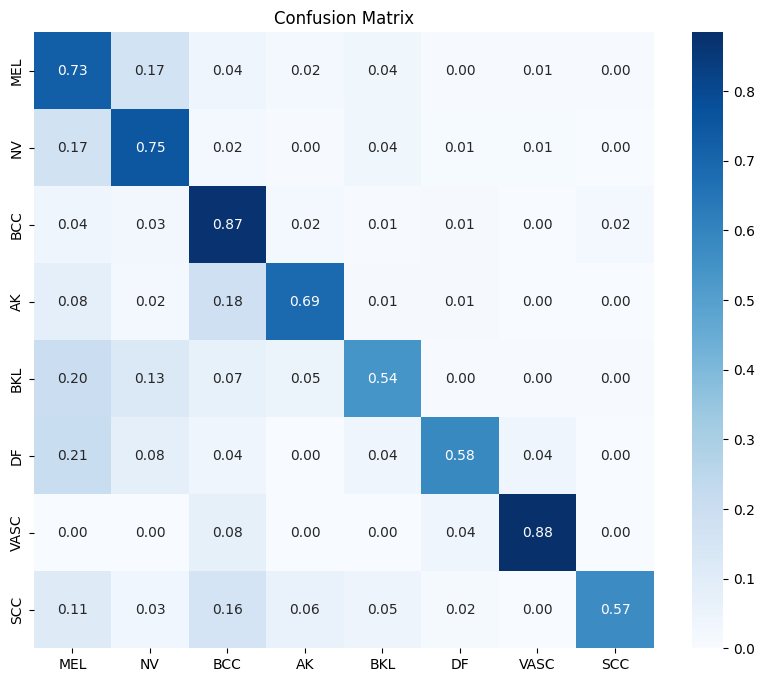

#####  test  #####


100%|██████████| 81/81 [01:23<00:00,  1.03s/it]


81/81 ━━━━━━━━━━━━━━━━━━━━ 206s 3s/step
              precision    recall  f1-score   support

         MEL       0.68      0.58      0.63       511
          NV       0.87      0.82      0.85      1288
         BCC       0.83      0.71      0.76       332
          AK       0.46      0.42      0.44        86
         BKL       0.50      0.73      0.60       263
          DF       0.29      0.83      0.43        24
        VASC       0.47      0.84      0.60        25
         SCC       0.43      0.63      0.51        63

    accuracy                           0.73      2592
   macro avg       0.57      0.70      0.60      2592
weighted avg       0.76      0.73      0.74      2592



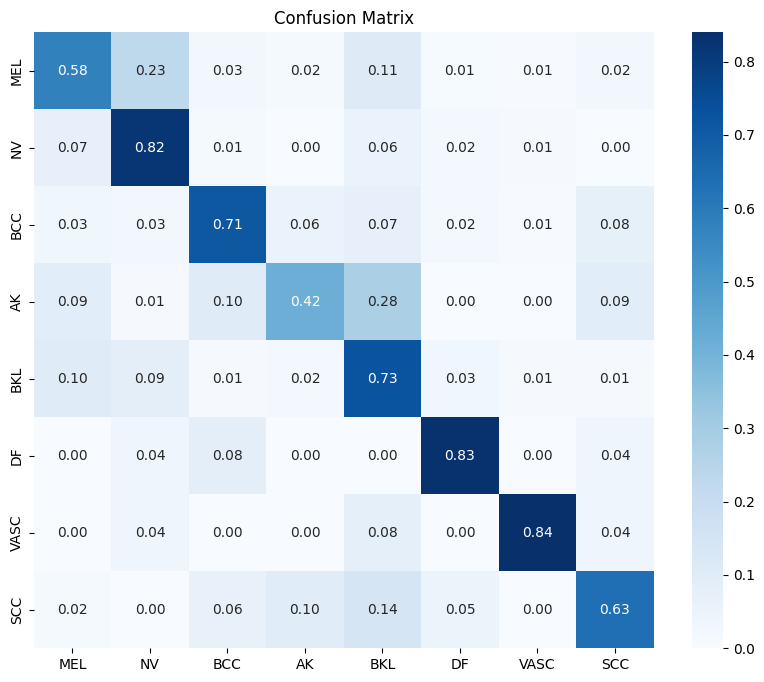

In [24]:
model = build_model()
model.load_weights("/Users/mac/Development/diploma/skin-mutation-detection/models/weights/efficientnetv2-s-onehot-deep-unified_softmask_65_baserun_2.keras")
test_model(model, history, 'efficientnetv2-s-segm-yolo-65-40', "/Users/mac/Development/diploma/skin-mutation-detection/models/results/efficientnetv2-s-segm-yolo-65-40")

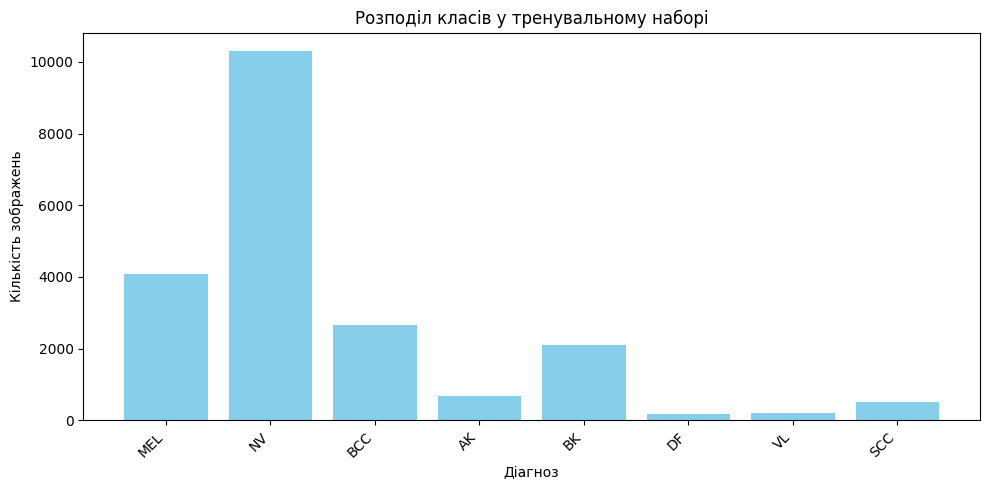

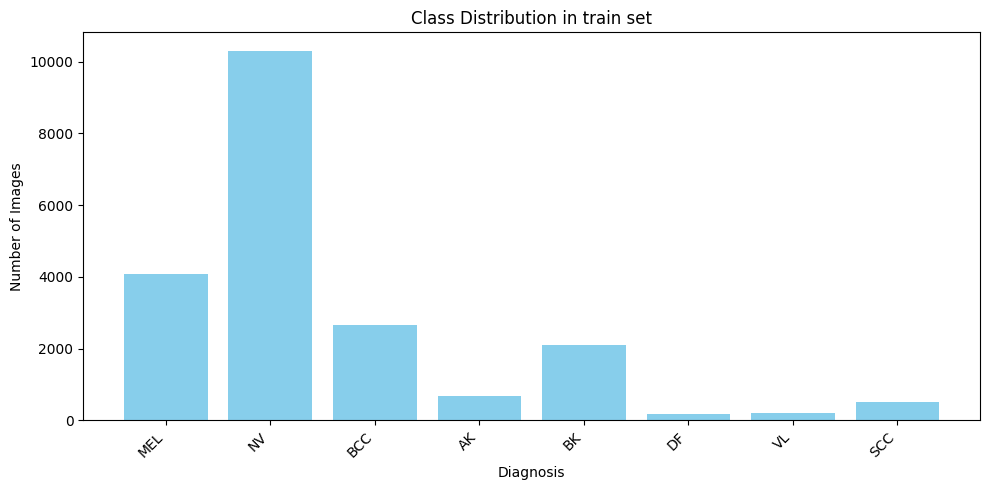

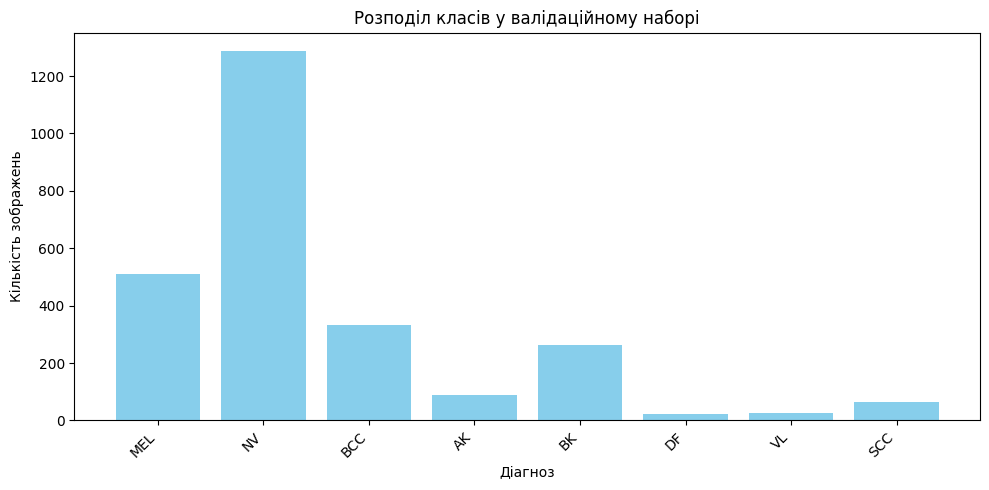

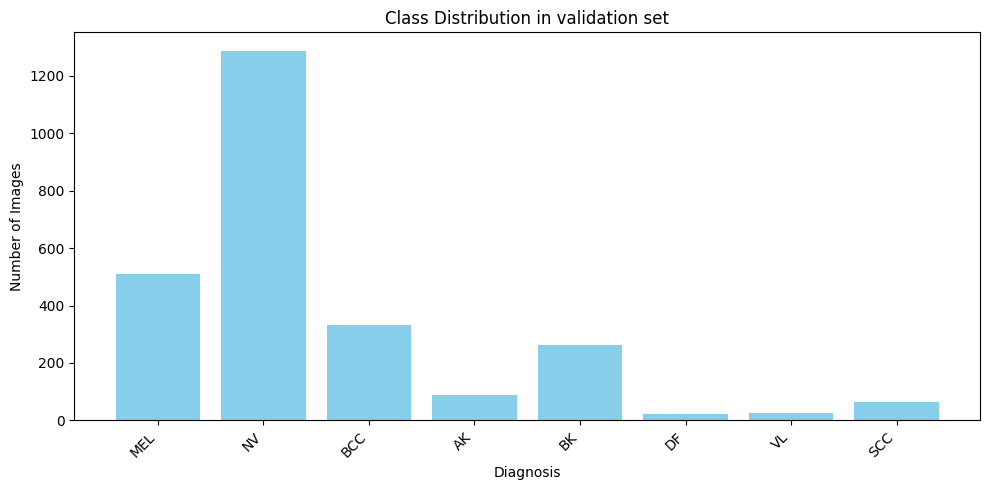

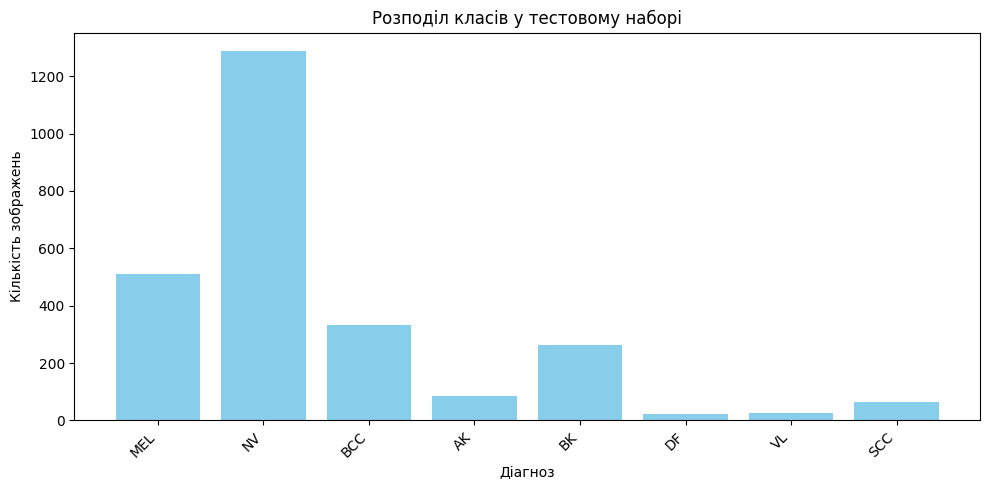

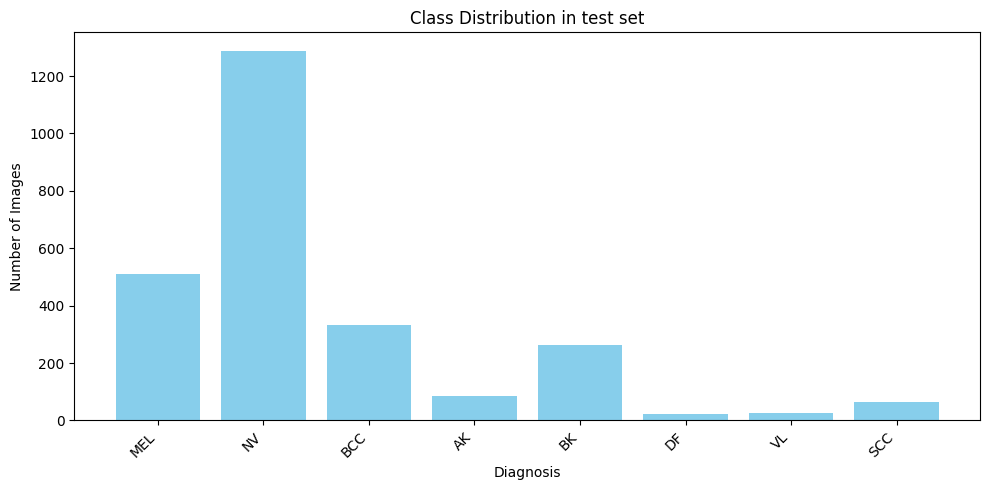

In [57]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# Utility: Extract and decode labels from a dataset
def extract_labels(dataset):
    decoded_labels = []
    for _, y in dataset.unbatch():
        label = tf.argmax(y).numpy()
        decoded_labels.append(label)
    return decoded_labels

# Utility: Plot distribution
def plot_distribution(labels, label_map, title, xlabel, ylabel):
    counts = Counter(labels)
    classes = sorted(label_map.keys())
    names = [label_map[c] for c in classes]
    values = [counts.get(c, 0) for c in classes]

    plt.figure(figsize=(10, 5))
    plt.bar(names, values, color='skyblue')
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
# Define your label map with abbreviations
label_map_en = {
    0: 'MEL',  # Melanoma
    1: 'NV',   # Nevus
    2: 'BCC',  # Basal Cell Carcinoma
    3: 'AK',   # Actinic Keratosis
    4: 'BK',   # Benign Keratosis
    5: 'DF',   # Dermatofibroma
    6: 'VL',   # Vascular Lesion
    7: 'SCC'   # Squamous Cell Carcinoma
}

# Extract labels
train_labels_decoded = extract_labels(train_dataset)
val_labels_decoded = extract_labels(val_dataset)
test_labels_decoded = extract_labels(test_dataset)

# Plot each in both languages
dataset_names = [
    ('train', 'тренувальному'),
    ('validation', 'валідаційному'),
    ('test', 'тестовому')
]

# Замість старого циклу
for (name_en, name_uk), labels in zip(dataset_names, [train_labels_decoded, val_labels_decoded, test_labels_decoded]):
    plot_distribution(
        labels,
        label_map_en,
        title=f'Розподіл класів у {name_uk} наборі',
        xlabel='Діагноз',
        ylabel='Кількість зображень'
    )
    plot_distribution(
        labels,
        label_map_en,
        title=f'Class Distribution in {name_en} set',
        xlabel='Diagnosis',
        ylabel='Number of Images'
    )


In [36]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

In [59]:
model = build_model()
model.load_weights("/Users/mac/Development/diploma/skin-mutation-detection/models/weights/efficientnet-v2-m-onehot-deep-split_baserun_2.keras")

/Users/mac/Library/Caches/pypoetry/virtualenvs/diploma-JhBIondL-py3.11/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 296 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [38]:
y_true = np.argmax(np.concatenate([y.numpy() for _, y in tqdm(test_dataset)]), axis=1)
y_pred = np.argmax(model.predict(test_dataset), axis=1)

100%|██████████| 81/81 [00:26<00:00,  3.01it/s]


81/81 ━━━━━━━━━━━━━━━━━━━━ 92s 955ms/step


100%|██████████| 81/81 [00:03<00:00, 23.52it/s]


81/81 ━━━━━━━━━━━━━━━━━━━━ 56s 668ms/step


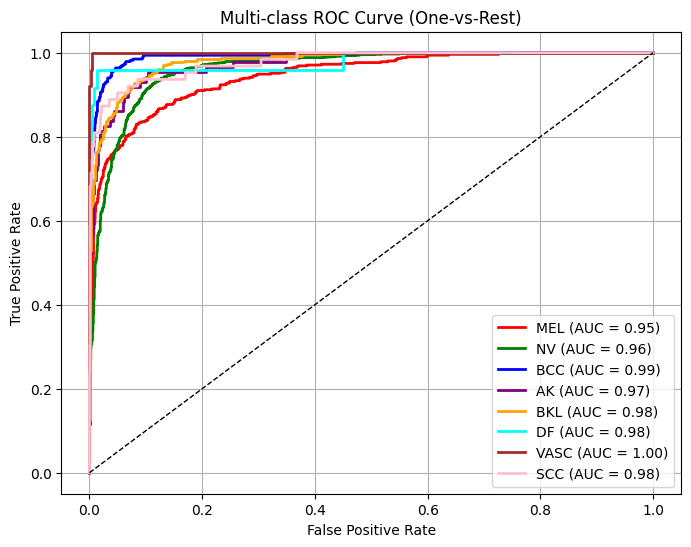

In [63]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay
import seaborn as sns
from tqdm import tqdm

# Step 1: Extract true labels and predicted probabilities
y_true = np.concatenate([y.numpy() for _, y in tqdm(test_dataset)])
y_true_int = np.argmax(y_true, axis=1) if y_true.ndim > 1 else y_true

y_probs = model.predict(test_dataset)  # probabilities from softmax layer
y_pred = np.argmax(y_probs, axis=1)    # class predictions

# Step 2: One-hot encode true labels
n_classes = y_probs.shape[1]
y_true_bin = label_binarize(y_true_int, classes=np.arange(n_classes))

# Step 3: Compute ROC curve and AUC
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Step 4: Plot ROC curves
plt.figure(figsize=(8, 6))
colors = ['red', 'green', 'blue', 'purple', 'orange', 'cyan', 'brown', 'pink', 'gray', 'olive']

for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], color=colors[i % len(colors)], lw=2,
             label=f'{LABELS[i]} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multi-class ROC Curve (One-vs-Rest)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


100%|██████████| 81/81 [00:04<00:00, 19.94it/s]


81/81 ━━━━━━━━━━━━━━━━━━━━ 56s 676ms/step
              precision    recall  f1-score   support

         MEL       0.76      0.79      0.78       511
          NV       0.91      0.89      0.90      1288
         BCC       0.85      0.92      0.89       332
          AK       0.73      0.67      0.70        86
         BKL       0.82      0.79      0.81       263
          DF       0.74      0.83      0.78        24
        VASC       0.85      0.92      0.88        25
         SCC       0.78      0.75      0.76        63

    accuracy                           0.85      2592
   macro avg       0.81      0.82      0.81      2592
weighted avg       0.85      0.85      0.85      2592



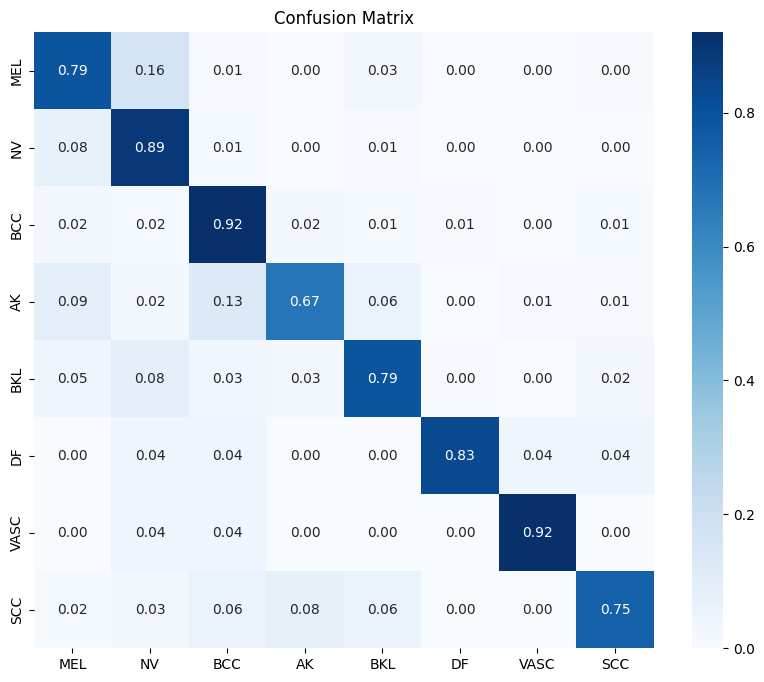

In [64]:
confusion(model, test_dataset)

In [ ]:
print(classification_report(y_true, y_pred, target_names=LABELS))

In [65]:
import json
TRAIN_RESULT_PATH = "/Users/mac/Development/diploma/skin-mutation-detection/models/results/efficientnetv2-s-smote-20.json"

with open(TRAIN_RESULT_PATH) as f:
    history = json.loads(f.read())

In [66]:
plot_history_ukr(history, output_dir="/Users/mac/Development/diploma/skin-mutation-detection/models/results/efficientnetv2-s-smote-20",
                 model_name='efficientnetv2-s-smote-20')

## Training EfficentNetV2-S for 20 more epochs (fine-tuning)


In [28]:
def build_model():
    base_model = EfficientNetV2S(weights="imagenet", include_top=False, input_shape=(*IMG_SIZE, 3))
    
    base_model.trainable = True
    for layer in base_model.layers[:int(len(base_model.layers) * 0.55)]:
        layer.trainable = False 

    inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
    x = base_model(inputs, training=False)

    x = layers.GlobalAveragePooling2D()(x) 

    x = layers.Dense(2048, activation="mish")(x)  
    x = layers.Dropout(0.4)(x)  
    x = layers.LayerNormalization()(x)  

    x = layers.Dense(1024, activation="mish")(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Dense(512, activation="mish")(x)
    x = layers.Dropout(0.2)(x)

    se = layers.Lambda(lambda t: tf.expand_dims(t, axis=-1))(x) 
    se = layers.GlobalAveragePooling1D()(se)
    se = layers.Dense(64, activation="relu")(se)
    se = layers.Dense(512, activation="sigmoid")(se)
    x = layers.Multiply()([x, se])

    outputs = layers.Dense(len(LABELS), activation="softmax")(x)
    model = models.Model(inputs, outputs)

    optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4)

    model.compile(
        optimizer=optimizer, 
        loss="categorical_crossentropy",  
        metrics=[
            "accuracy",
            tf.keras.metrics.AUC(name="auc"),
            tf.keras.metrics.Precision(name="precision"), 
            tf.keras.metrics.Recall(name="recall")
        ]
)

In [10]:
def load_image(file_path, label):
    img = tf.io.read_file(file_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.keras.applications.efficientnet.preprocess_input(img)
    return img, label

def preprocess_and_augment(file_path, label):
    img, label = load_image(file_path, label)
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    img = tf.image.random_brightness(img, max_delta=0.2)
    img = tf.image.random_contrast(img, lower=0.8, upper=1.2)
    return img, label

train_dataset = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
train_dataset = train_dataset.map(preprocess_and_augment).shuffle(512).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_dataset = tf.data.Dataset.from_tensor_slices((val_paths, val_labels))
val_dataset = val_dataset.map(load_image).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_dataset = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
test_dataset = test_dataset.map(load_image).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test2_dataset = tf.data.Dataset.from_tensor_slices((test_paths_2, test_labels_2))
test2_dataset = test2_dataset.map(load_image).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


In [11]:
model.load_weights("/Users/mac/Development/diploma/skin-mutation-detection/models/weights/efficientnet-v2-m-onehot-deep-split_baserun_2.keras")

/Users/mac/Library/Caches/pypoetry/virtualenvs/diploma-JhBIondL-py3.11/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 296 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [75]:
MODEL_NAME = "efficientnetv2-s-onehot-deep-no-segm-unified-fixed-se-finetune-baserun2-055"
EPOCHS = 20

In [76]:
checkpoint = ModelCheckpoint(f"{MODEL_NAME}_baserun.keras", monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", 
                                                    factor=0.5, 
                                                    patience=3, 
                                                    min_lr=1e-6, 
                                                    verbose=1)
                                                    
history = model.fit(train_dataset, validation_data=val_dataset, epochs=EPOCHS, callbacks=[checkpoint, lr_scheduler],
                    class_weight=class_weights_dict)

Epoch 1/20
648/648 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8805 - auc: 0.9898 - loss: 0.1876 - precision: 0.8902 - recall: 0.8729
Epoch 1: val_accuracy improved from -inf to 0.79699, saving model to efficientnetv2-s-onehot-deep-no-segm-unified-fixed-se-finetune-baserun2-055_baserun.keras
648/648 ━━━━━━━━━━━━━━━━━━━━ 1012s 1s/step - accuracy: 0.8805 - auc: 0.9898 - loss: 0.1876 - precision: 0.8902 - recall: 0.8728 - val_accuracy: 0.7970 - val_auc: 0.9623 - val_loss: 0.7512 - val_precision: 0.8059 - val_recall: 0.7916 - learning_rate: 1.0000e-04
Epoch 2/20
648/648 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8762 - auc: 0.9897 - loss: 0.2138 - precision: 0.8889 - recall: 0.8647
Epoch 2: val_accuracy improved from 0.79699 to 0.80973, saving model to efficientnetv2-s-onehot-deep-no-segm-unified-fixed-se-finetune-baserun2-055_baserun.keras
648/648 ━━━━━━━━━━━━━━━━━━━━ 922s 1s/step - accuracy: 0.8762 - auc: 0.9897 - loss: 0.2138 - precision: 0.8889 - recall: 0.8647 - val_accuracy: 0.8

In [16]:
model.load_weights("/Users/mac/Development/diploma/skin-mutation-detection/models/notebooks/efficientnetv2-s-onehot-deep-no-segm-unified-fixed-se-finetune-baserun2-055_baserun.keras")

/Users/mac/Library/Caches/pypoetry/virtualenvs/diploma-JhBIondL-py3.11/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 296 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


100%|██████████| 81/81 [00:03<00:00, 20.98it/s]


81/81 ━━━━━━━━━━━━━━━━━━━━ 71s 729ms/step


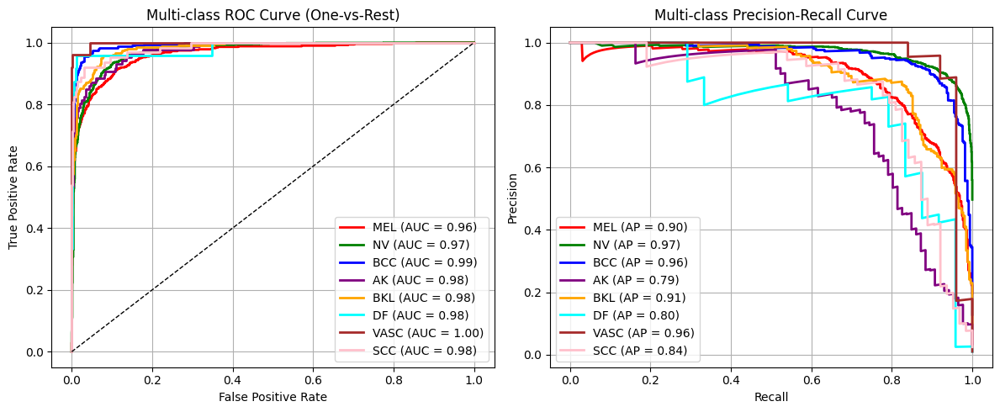

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, precision_recall_curve
from tqdm import tqdm

# Step 1: Extract true labels and predicted probabilities
y_true = np.concatenate([y.numpy() for _, y in tqdm(test_dataset)])
y_true_int = np.argmax(y_true, axis=1) if y_true.ndim > 1 else y_true

y_probs = model.predict(test_dataset)  # probabilities from softmax layer
y_pred = np.argmax(y_probs, axis=1)    # class predictions

# Step 2: One-hot encode true labels
n_classes = y_probs.shape[1]
y_true_bin = label_binarize(y_true_int, classes=np.arange(n_classes))

# Step 3: Compute ROC curve and AUC
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Step 4: Compute Precision-Recall curve and Average Precision (AP)
precision = dict()
recall = dict()
average_precision = dict()

for i in range(n_classes):
    precision[i], recall[i], _ = precision_recall_curve(y_true_bin[:, i], y_probs[:, i])
    # Average precision summarizes the precision-recall curve
    average_precision[i] = auc(recall[i], precision[i])

# Step 5: Plot ROC curves
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
colors = ['red', 'green', 'blue', 'purple', 'orange', 'cyan', 'brown', 'pink', 'gray', 'olive']

for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], color=colors[i % len(colors)], lw=2,
             label=f'{LABELS[i]} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multi-class ROC Curve (One-vs-Rest)')
plt.legend(loc='lower right')
plt.grid(True)

# Step 6: Plot Precision-Recall curves
plt.subplot(1, 2, 2)

for i in range(n_classes):
    plt.plot(recall[i], precision[i], color=colors[i % len(colors)], lw=2,
             label=f'{LABELS[i]} (AP = {average_precision[i]:.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Multi-class Precision-Recall Curve')
plt.legend(loc='lower left')
plt.grid(True)

plt.tight_layout()
plt.show()


{'accuracy': [0.8711653351783752, 0.8755546808242798, 0.8858768939971924, 0.8863109946250916, 0.8794617056846619, 0.8851534128189087, 0.9048331379890442, 0.9193999767303467, 0.9272621870040894, 0.925381064414978, 0.9358962178230286, 0.9377291202545166, 0.9450125694274902, 0.9477618932723999, 0.9480995535850525, 0.9527300596237183, 0.9551417827606201, 0.9575535655021667, 0.9570711851119995, 0.9607370495796204], 'auc': [0.9887331128120422, 0.9893907904624939, 0.9906935691833496, 0.9907284379005432, 0.9891480207443237, 0.9905214905738831, 0.9937934875488281, 0.9950124025344849, 0.9957287311553955, 0.996090829372406, 0.9962932467460632, 0.9966131448745728, 0.9971157312393188, 0.9976624846458435, 0.9977185130119324, 0.9982383251190186, 0.9983043074607849, 0.9980801343917847, 0.9983984231948853, 0.9984728097915649], 'loss': [0.21259236335754395, 0.21949028968811035, 0.1984662413597107, 0.20524217188358307, 0.23031488060951233, 0.2098921835422516, 0.14412599802017212, 0.13231542706489563, 0.1

100%|██████████| 648/648 [03:18<00:00,  3.27it/s]


648/648 ━━━━━━━━━━━━━━━━━━━━ 443s 681ms/step
              precision    recall  f1-score   support

         MEL       0.98      1.00      0.99      4085
          NV       1.00      0.99      0.99     10300
         BCC       0.99      1.00      1.00      2659
          AK       1.00      1.00      1.00       694
         BKL       0.99      1.00      0.99      2099
          DF       0.98      1.00      0.99       191
        VASC       1.00      1.00      1.00       202
         SCC       1.00      1.00      1.00       502

    accuracy                           0.99     20732
   macro avg       0.99      1.00      0.99     20732
weighted avg       0.99      0.99      0.99     20732



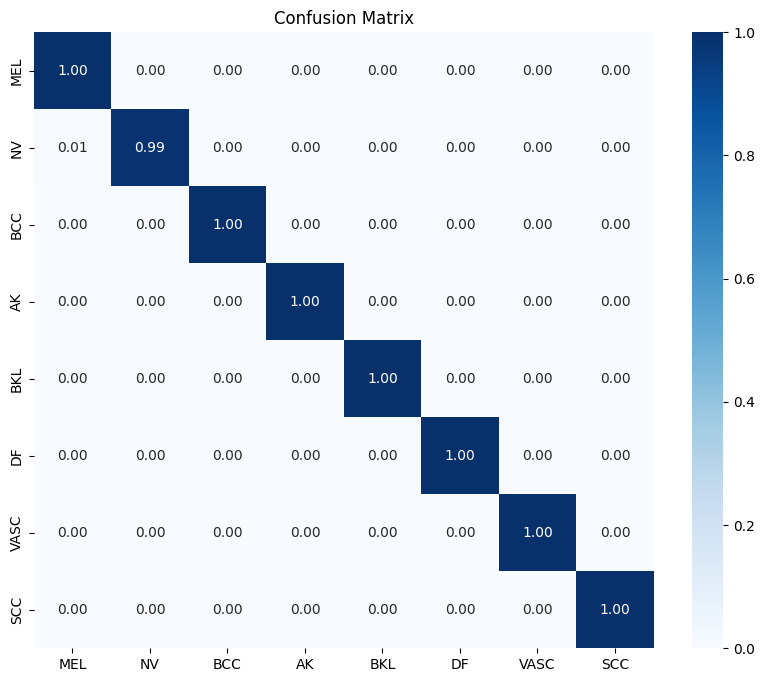

#####  val  #####


100%|██████████| 81/81 [00:03<00:00, 26.14it/s]


81/81 ━━━━━━━━━━━━━━━━━━━━ 61s 745ms/step
              precision    recall  f1-score   support

         MEL       0.80      0.83      0.82       510
          NV       0.92      0.90      0.91      1287
         BCC       0.90      0.93      0.91       332
          AK       0.72      0.68      0.70        87
         BKL       0.78      0.77      0.77       262
          DF       0.61      0.58      0.60        24
        VASC       0.85      0.85      0.85        26
         SCC       0.65      0.70      0.67        63

    accuracy                           0.86      2591
   macro avg       0.78      0.78      0.78      2591
weighted avg       0.86      0.86      0.86      2591



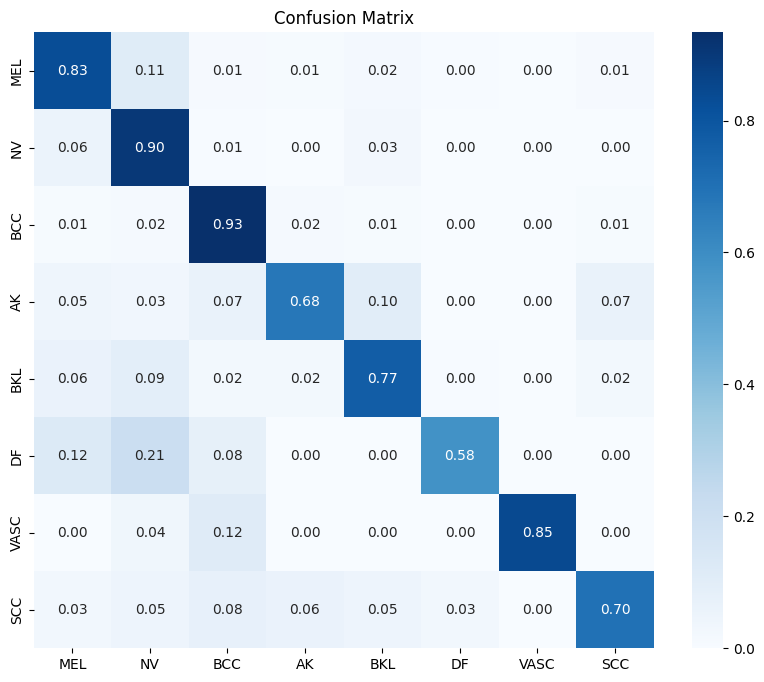

#####  test  #####


100%|██████████| 81/81 [00:03<00:00, 23.51it/s]


81/81 ━━━━━━━━━━━━━━━━━━━━ 54s 660ms/step
              precision    recall  f1-score   support

         MEL       0.78      0.83      0.81       511
          NV       0.93      0.90      0.91      1288
         BCC       0.87      0.92      0.89       332
          AK       0.79      0.69      0.73        86
         BKL       0.84      0.83      0.84       263
          DF       0.77      0.83      0.80        24
        VASC       0.82      0.92      0.87        25
         SCC       0.81      0.79      0.80        63

    accuracy                           0.87      2592
   macro avg       0.83      0.84      0.83      2592
weighted avg       0.87      0.87      0.87      2592



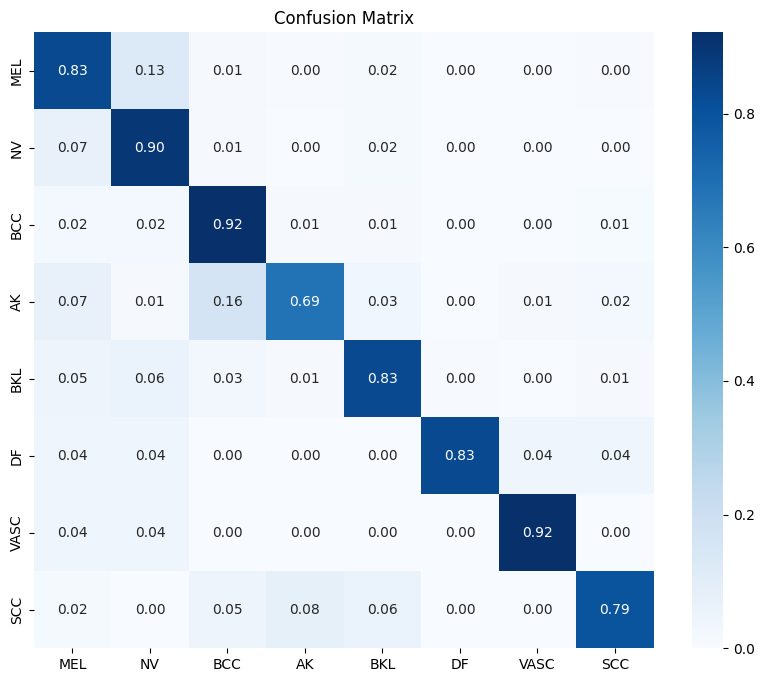

In [78]:
test_model(model, history.history, 'efficientnetv2-s-no-segm-fixed-se-finetune-baserun2-055', "/Users/mac/Development/diploma/skin-mutation-detection/models/results/efficientnetv2-s-no-segm-fixed-se-finetune-baserun2-055")

## Testing on ISIC 2019

In [26]:
model.load_weights("/Users/mac/Development/diploma/skin-mutation-detection/models/notebooks/efficientnetv2-s-onehot-deep-no-segm-unified-fixed-se-finetune-baserun2-055_baserun.keras")

/Users/mac/Library/Caches/pypoetry/virtualenvs/diploma-JhBIondL-py3.11/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 296 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [18]:
TEST3_IMAGE_DIR = "/Users/mac/Development/diploma/skin-mutation-detection/data/test/ISIC_2019_Test_Input"
TEST3_GROUNDTRUTH_PATH = "/Users/mac/Development/diploma/skin-mutation-detection/data/test/ISIC_2019_Test_GroundTruth.csv"

In [20]:
isic_test_groundtruth = read_ds(TEST3_GROUNDTRUTH_PATH)

In [21]:
test_paths_2, test_labels_2 = get_image_paths_and_labels(isic_test_groundtruth, TEST3_IMAGE_DIR)

In [22]:
isic_test_dataset = tf.data.Dataset.from_tensor_slices((test_paths_2, test_labels_2))
isic_test_dataset = isic_test_dataset.map(load_image).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [ ]:
confusion(model, isic_test_dataset)

In [4]:
base_model = EfficientNetV2S(weights="imagenet", include_top=False, input_shape=(456, 456, 3))

2025-05-21 00:58:54.542007: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1 Pro
2025-05-21 00:58:54.542181: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 32.00 GB
2025-05-21 00:58:54.542185: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 10.67 GB
I0000 00:00:1747778334.542742  323781 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1747778334.542801  323781 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [7]:
for i in [0.1, 0.3, 0.5]:
    print(len(base_model.layers) * i)
# base_model[:int()]
print(f"out of {len(base_model.layers)}")

51.300000000000004
153.9
256.5
out of 513


In [8]:
total_layers = len(base_model.layers)
print(f"Total layers in base model: {total_layers}")

for i in [0.1, 0.3, 0.5]:
    cutoff = int(total_layers * i)
    selected_layers = base_model.layers[:cutoff]

    param_count = sum([np.sum(layer.count_params()) for layer in selected_layers])
    
    print(f"{int(i*100)}% of layers: {cutoff} layers → {param_count:,} parameters")


Total layers in base model: 513
10% of layers: 51 layers → 577,960 parameters
30% of layers: 153 layers → 1,838,680 parameters
50% of layers: 256 layers → 4,535,272 parameters


In [11]:
recall = 0.94
precision = 0.83
f1 = 2 * (precision * recall) / (precision + recall)

In [12]:
f1

0.8815819209039547

In [104]:
model.export(f"/Users/mac/Development/diploma/skin-mutation-detection/models/weights/efficientnetv2-s-onehot-deep-unified-softmask-se-mish-finetune-05")

INFO:tensorflow:Assets written to: /Users/mac/Development/diploma/skin-mutation-detection/models/weights/efficientnetv2-s-onehot-deep-unified-softmask-se-mish-finetune-05/assets


INFO:tensorflow:Assets written to: /Users/mac/Development/diploma/skin-mutation-detection/models/weights/efficientnetv2-s-onehot-deep-unified-softmask-se-mish-finetune-05/assets


Saved artifact at '/Users/mac/Development/diploma/skin-mutation-detection/models/weights/efficientnetv2-s-onehot-deep-unified-softmask-se-mish-finetune-05'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 456, 456, 3), dtype=tf.float32, name='keras_tensor_20671')
Output Type:
  TensorSpec(shape=(None, 8), dtype=tf.float32, name=None)
Captures:
  13568381136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  14366357072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  14366346704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13568383248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13568380368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  14366351504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  14366355152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  14366352272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  14366348624: TensorSpec(shape=(), dtype=tf.resource, name=Non

# Inference

In [94]:
import time
class SkinCancerClassifier:
    def __init__(self, model, csv_path):
        self.model = model
        self.labels_df = pd.read_csv(csv_path)
        self.labels_df['image'] = self.labels_df['image'].astype(str)

    def load_image(self, file_path):
        img = tf.io.read_file(file_path)
        img = tf.image.decode_jpeg(img, channels=3)
        img = tf.image.resize(img, IMG_SIZE)
        img = tf.keras.applications.efficientnet.preprocess_input(img)
        return img

    def get_true_label(self, file_path):
        image_id = os.path.splitext(os.path.basename(file_path))[0]
        row = self.labels_df[self.labels_df['image'] == image_id]
        if row.empty:
            return "UNK"
        one_hot = row[LABELS].values[0]
        index = int(tf.argmax(one_hot).numpy())
        return LABELS[index]

    def predict(self, file_path):
        img = self.load_image(file_path)
        img = tf.expand_dims(img, axis=0)

        start_time = time.time()
        print(self.model)
        predictions = self.model.predict(img)
        elapsed_time = time.time() - start_time
        print(predictions[0])
        predicted_index = tf.argmax(predictions[0]).numpy()
        confidence = predictions[0][predicted_index]
        predicted_label = LABELS[predicted_index]
        true_label = self.get_true_label(file_path)

        return {
            "predicted_label": predicted_label,
            "confidence": confidence,
            "true_label": true_label,
            "inference_time_sec": elapsed_time
        }

In [97]:
class SkinCancerVisualizer:
    def __init__(self, classifier, img_size=(224, 224), save_path="/Users/mac/Development/diploma/skin-mutation-detection/runs/classify/test"):
        self.classifier = classifier
        self.img_size = img_size
        self.save_path = save_path

    def visualize(self, file_path):
        # Get prediction data
        result = self.classifier.predict(file_path)
        predicted_label = result["predicted_label"]
        true_label = result["true_label"]
        confidence = result["confidence"]
        time_taken = result["inference_time_sec"]

        # Load and prepare image for display
        raw_img = tf.io.read_file(file_path)
        raw_img = tf.image.decode_jpeg(raw_img, channels=3)
        raw_img = tf.image.resize(raw_img, self.img_size).numpy().astype("uint8")
        
        # Title and color logic
        correct = predicted_label == true_label
        title_color = "green" if correct else "red"
        title_text = f"Sample Name: {os.path.basename(file_path)}\nPredicted: {predicted_label} ({confidence:.2%})\nTrue: {true_label}\nTime: {time_taken:.3f} sec"

        # Display image and prediction
        plt.figure(figsize=(6, 6))
        plt.imshow(raw_img)
        plt.title(title_text, color=title_color, fontsize=12)
        plt.axis("off")
        plt.savefig(os.path.join(self.save_path, os.path.basename(file_path)), bbox_inches=None, pad_inches=0)
        plt.show()

In [91]:
def build_model():
    base_model = EfficientNetV2S(weights="imagenet", include_top=False, input_shape=(*IMG_SIZE, 3))
    
    base_model.trainable = True
    for layer in base_model.layers[:int(len(base_model.layers) * 0.55)]:
        layer.trainable = False 

    inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
    x = base_model(inputs, training=False)

    x = layers.GlobalAveragePooling2D()(x) 

    x = layers.Dense(2048, activation="mish")(x)  
    x = layers.Dropout(0.4)(x)  
    x = layers.LayerNormalization()(x)  

    x = layers.Dense(1024, activation="mish")(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Dense(512, activation="mish")(x)
    x = layers.Dropout(0.2)(x)

    se = layers.Lambda(lambda t: tf.expand_dims(t, axis=-1))(x) 
    se = layers.GlobalAveragePooling1D()(se)
    se = layers.Dense(64, activation="relu")(se)
    se = layers.Dense(512, activation="sigmoid")(se)
    x = layers.Multiply()([x, se])

    outputs = layers.Dense(len(LABELS), activation="softmax")(x)
    model = models.Model(inputs, outputs)

    optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4)

    model.compile(
        optimizer=optimizer, 
        loss="categorical_crossentropy",  
        metrics=[
            "accuracy",
            tf.keras.metrics.AUC(name="auc"),
            tf.keras.metrics.Precision(name="precision"), 
            tf.keras.metrics.Recall(name="recall")
        ]    
    )
    
    return model


In [92]:
model = build_model()
tf.config.optimizer.set_jit(True)

<Functional name=functional_37, built=True>


/Users/mac/Library/Caches/pypoetry/virtualenvs/diploma-JhBIondL-py3.11/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 296 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


<Functional name=functional_37, built=True>
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 278ms/step
[1.5644243e-04 9.9979478e-01 2.9205735e-11 9.6250057e-12 4.8768678e-05
 8.0622710e-11 1.5756974e-10 3.4362790e-11]


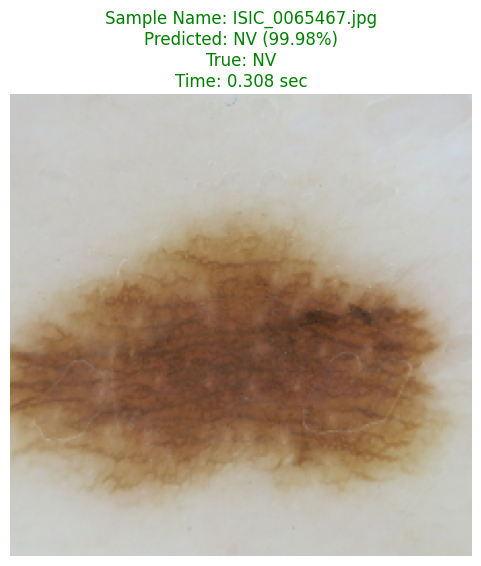

<Functional name=functional_37, built=True>
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step
[1.2433568e-03 9.9868447e-01 6.9248813e-06 5.8946145e-05 6.1328465e-06
 1.4784587e-08 4.9659057e-08 1.1054515e-07]


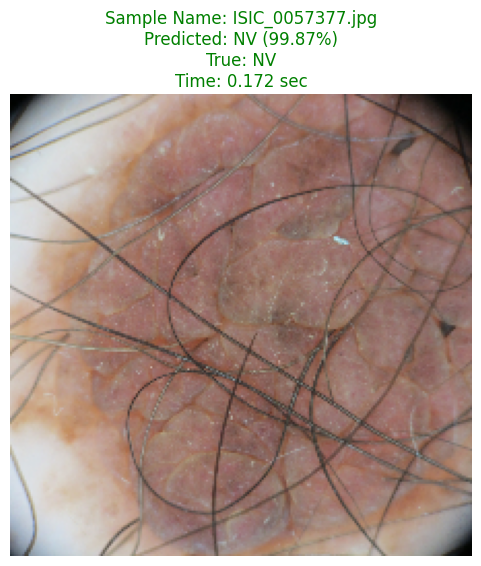

<Functional name=functional_37, built=True>
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
[3.3473559e-06 9.9997914e-01 1.4260463e-08 1.8912785e-11 1.7497492e-05
 1.0254240e-08 7.0012424e-10 8.2144930e-11]


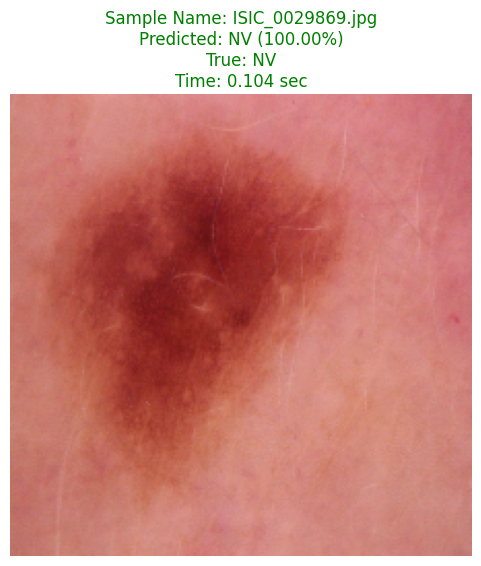

<Functional name=functional_37, built=True>
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step
[4.9041940e-08 1.2968593e-07 3.8341543e-07 5.2076384e-08 5.9664998e-08
 2.1923785e-09 2.9221969e-11 9.9999940e-01]


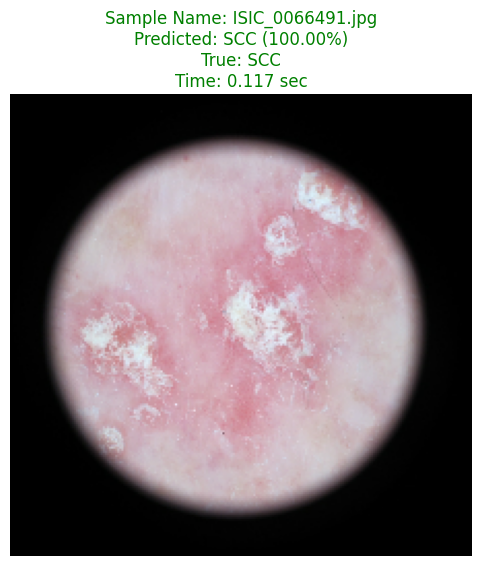

<Functional name=functional_37, built=True>
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
[7.7603370e-05 9.5450151e-01 4.5408264e-02 2.0527926e-09 1.2614320e-05
 4.8810442e-08 4.4179991e-08 1.8765869e-09]


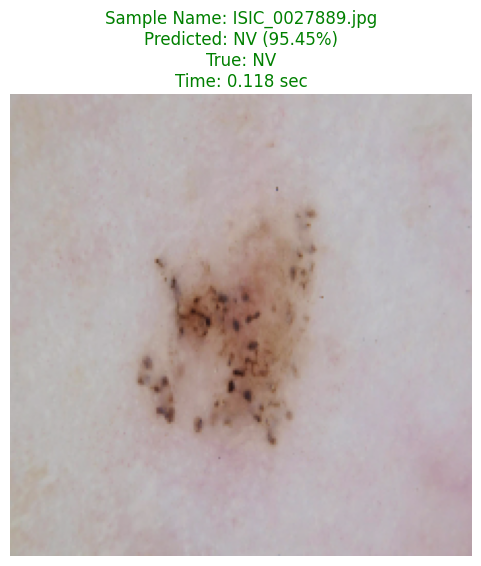

<Functional name=functional_37, built=True>
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
[4.1736328e-04 9.9950874e-01 2.5016000e-10 9.4911501e-10 7.3847797e-05
 2.1063333e-10 2.4697971e-10 1.2295072e-09]


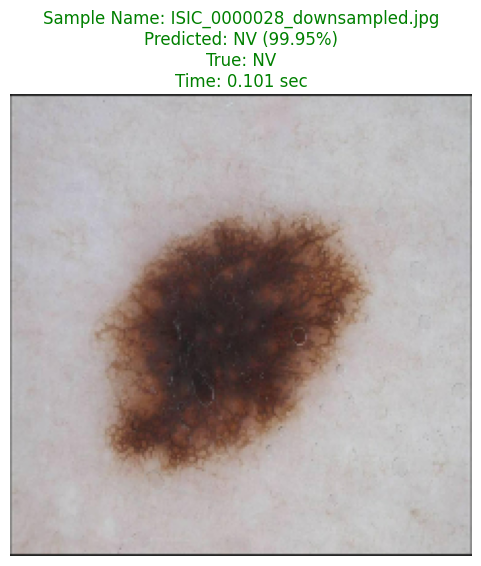

<Functional name=functional_37, built=True>
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step
[4.6376495e-05 9.9962914e-01 3.2263002e-04 2.4412134e-11 1.8725730e-06
 2.6631448e-09 9.3707253e-10 5.9354652e-12]


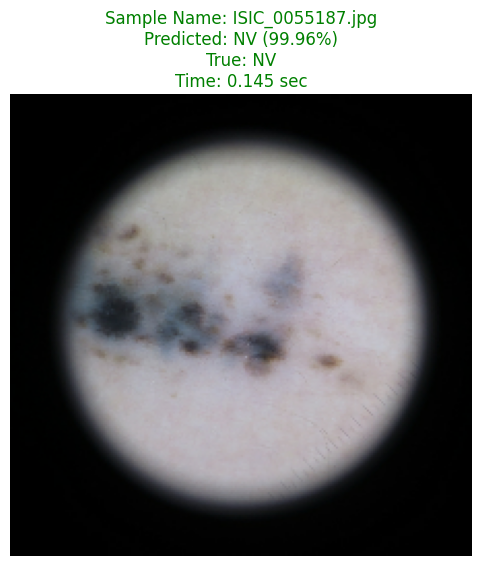

<Functional name=functional_37, built=True>
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
[4.3554578e-04 9.9956435e-01 2.5477629e-08 1.2238875e-09 6.7611698e-09
 1.6885702e-09 9.0773533e-08 4.1415920e-12]


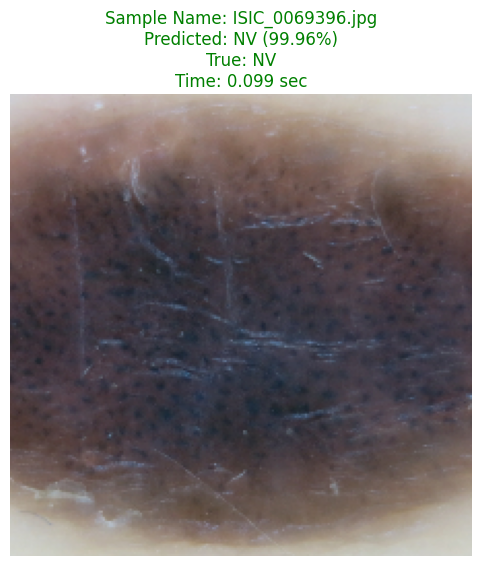

<Functional name=functional_37, built=True>
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
[3.3745696e-06 9.9999666e-01 2.3573190e-12 1.3288148e-14 3.5805967e-09
 1.3148113e-12 1.8237974e-10 3.2220862e-15]


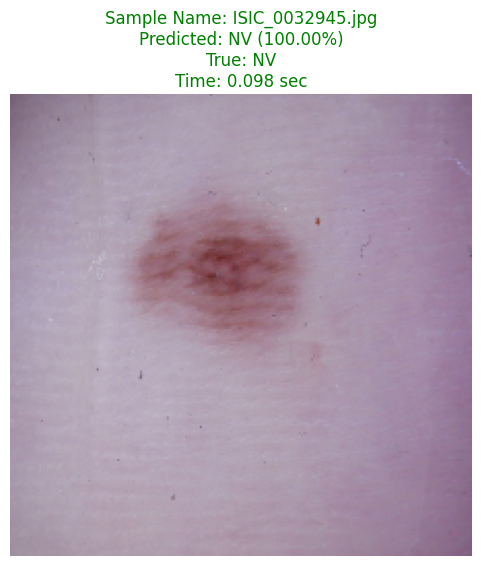

<Functional name=functional_37, built=True>
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
[8.7846447e-06 4.0015704e-05 9.9993455e-01 1.3112625e-06 9.2335773e-07
 5.5238894e-07 2.8392718e-08 1.3864448e-05]


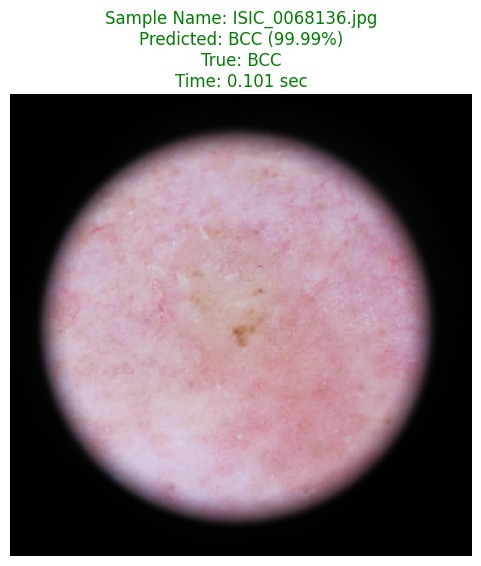

<Functional name=functional_37, built=True>
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
[9.8294210e-01 7.9440139e-03 1.3581068e-07 2.1473273e-08 9.1136703e-03
 1.0330912e-08 6.1018596e-10 6.3893971e-08]


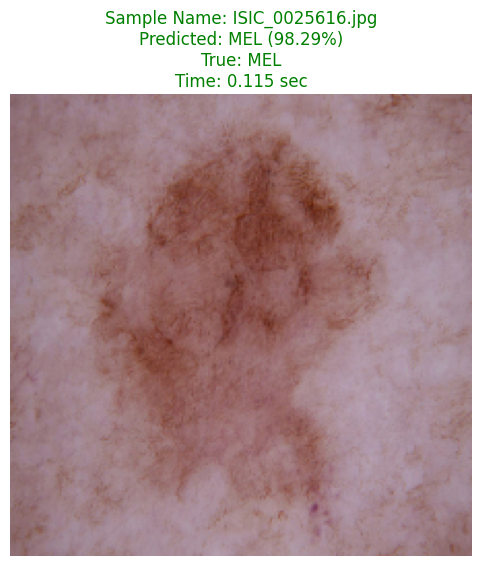

<Functional name=functional_37, built=True>
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step
[4.5495735e-06 9.9998581e-01 1.4476955e-08 5.5751757e-11 9.6631702e-06
 3.7346510e-08 5.6006009e-09 1.5481956e-09]


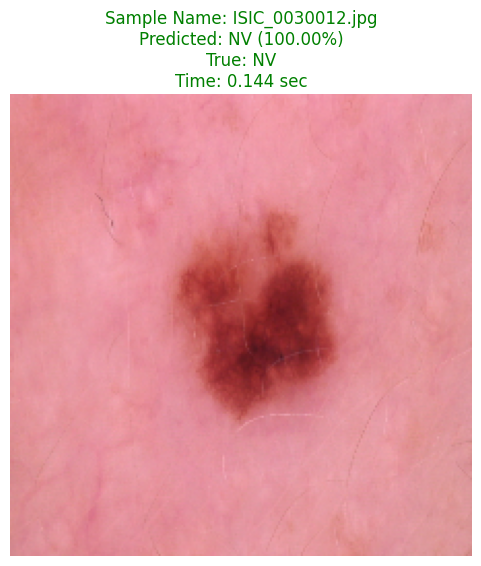

<Functional name=functional_37, built=True>
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
[2.3099930e-05 9.9997640e-01 2.2260270e-10 5.8319100e-12 3.4649497e-07
 1.2209674e-07 9.1578405e-11 9.5452557e-10]


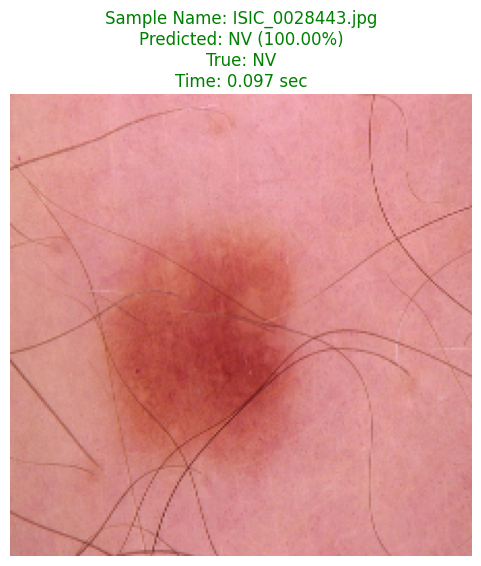

<Functional name=functional_37, built=True>
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
[9.9992645e-01 7.3496514e-05 2.4539428e-08 2.5044539e-11 6.9771050e-10
 4.0700721e-11 5.7491191e-12 2.9595613e-09]


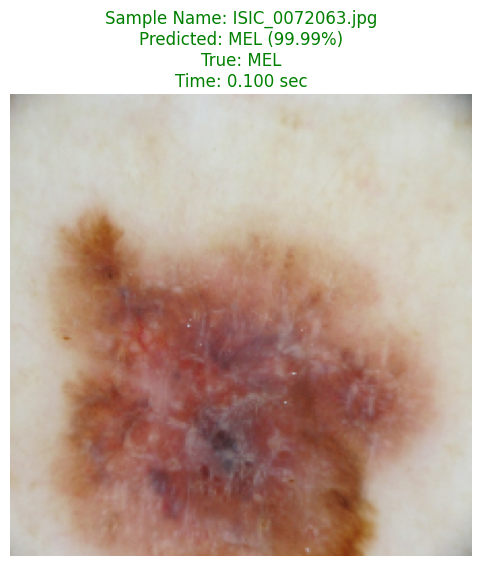

<Functional name=functional_37, built=True>
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
[7.0492179e-06 8.6928339e-06 9.9995220e-01 4.7345347e-06 2.4696731e-06
 2.5620932e-07 2.8394737e-08 2.4525076e-05]


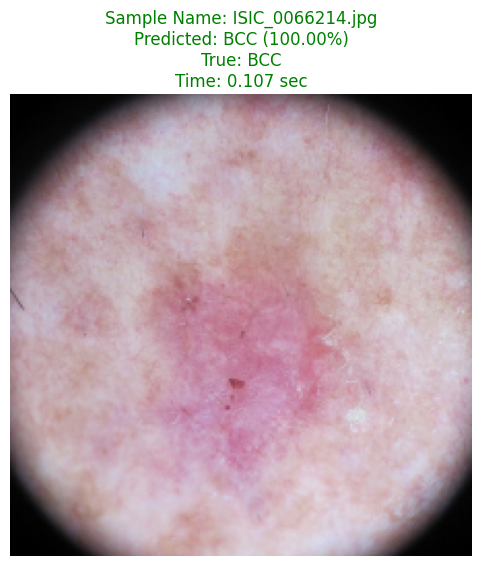

<Functional name=functional_37, built=True>
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
[5.1174277e-01 4.8825476e-01 1.1799969e-08 1.1425351e-07 9.3933943e-07
 2.1044588e-08 6.8729922e-10 1.5164544e-06]


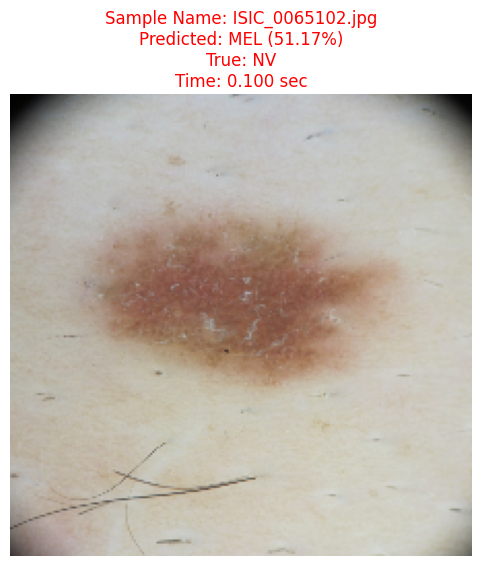

<Functional name=functional_37, built=True>
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step
[2.6767293e-05 9.9997246e-01 4.3933152e-08 2.0302039e-12 6.9590823e-07
 3.5235571e-11 9.6395274e-11 1.1640771e-12]


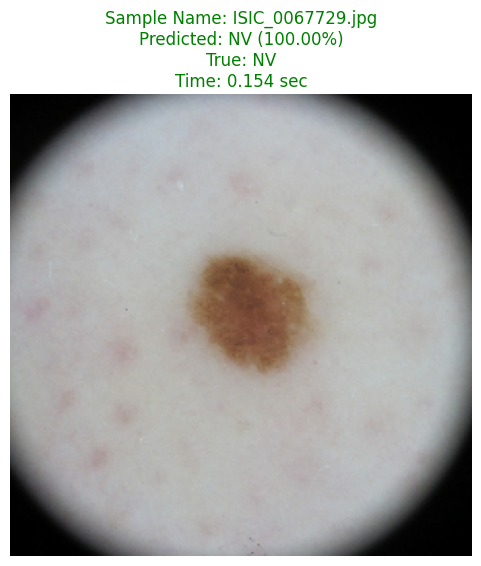

<Functional name=functional_37, built=True>
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
[1.32122591e-06 9.99998689e-01 4.61057220e-10 2.16049970e-13
 3.52731995e-08 1.43125225e-11 1.38151863e-08 1.06280930e-11]


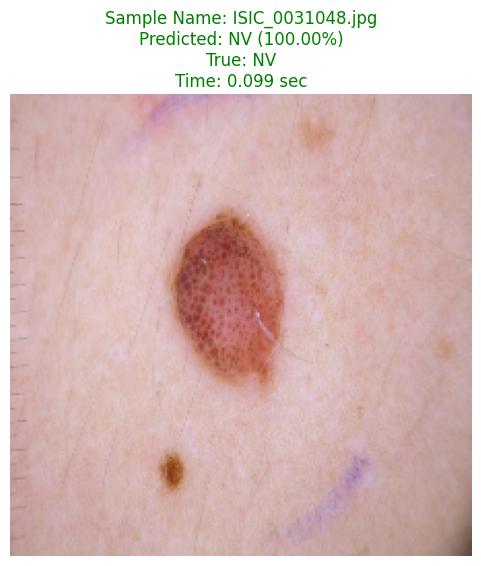

<Functional name=functional_37, built=True>
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
[1.8381499e-01 8.1618500e-01 1.7717469e-10 5.1658029e-11 7.3681072e-08
 8.5376939e-10 1.2188599e-10 1.3733623e-11]


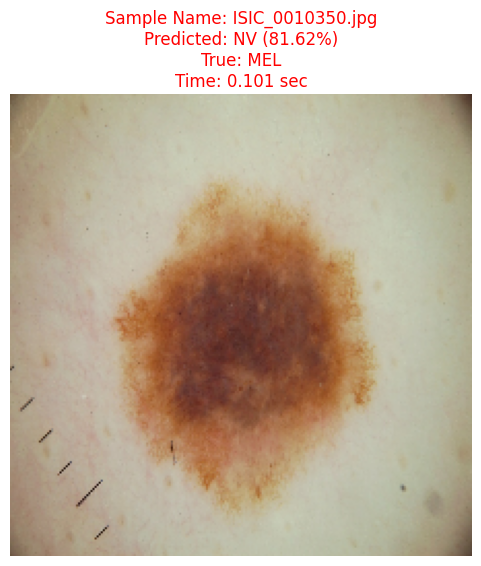

<Functional name=functional_37, built=True>
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
[3.26470087e-07 9.99810755e-01 1.00246222e-09 4.95042917e-13
 1.88889739e-04 1.40645126e-11 5.57896507e-11 1.08088506e-13]


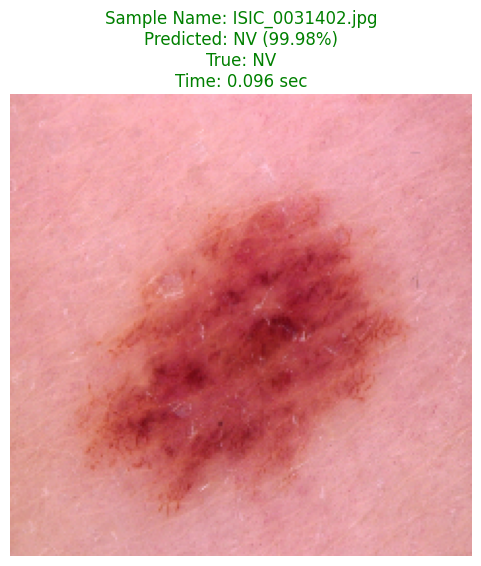

<Functional name=functional_37, built=True>
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
[1.0912882e-03 9.9890876e-01 6.4568741e-12 3.3726695e-12 1.4099278e-09
 7.4812526e-12 1.3216490e-11 1.6472370e-14]


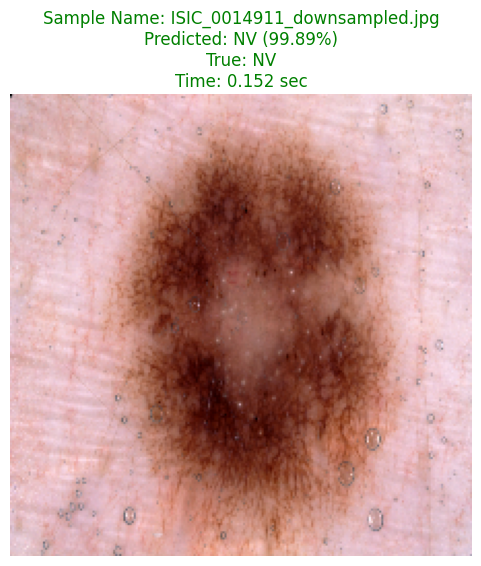

In [98]:
print(model)
model.load_weights("/Users/mac/Development/diploma/skin-mutation-detection/models/notebooks/efficientnetv2-s-onehot-deep-no-segm-unified-fixed-se-finetune-baserun2-055_baserun.keras")
classifier = SkinCancerClassifier(model, "/Users/mac/Development/diploma/skin-mutation-detection/unified_dataset/gt.csv")
visualizer = SkinCancerVisualizer(classifier)

TEST_IMAGES_PATH = "/Users/mac/Development/diploma/skin-mutation-detection/unified_dataset/images"
test_dataset = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
i = 0
for base_name, label in test_dataset:
    if i > 20:
        break
    base_name = base_name.numpy().decode()
    if base_name.split('.')[1] != 'jpg':
        print(f"{base_name} skipped")
        continue
    file = os.path.join(TEST_IMAGES_PATH, base_name)
    visualizer.visualize(file)
    i = i + 1
# Output:
# {
#   'predicted_label': 'NV',
#   'confidence': 0.97,
#   'true_label': 'NV',
#   'inference_time_sec': 0.0231
# }
